# HLCAv1 extended comparison

In [1]:
import scanpy as sc
# import rapids_singlecell as rsc
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from pprint import pprint

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

import importlib
import scatlastb_utils as atl

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from misc import clean_prefixes

In [4]:
integrations = [
    'HLCAv1',
    'highQC',
]

## Read data

In [5]:
adata = atl.io.read_anndata(
    'data/pipeline/HLCAv1/QC/marker_genes/dataset~HLCAv1_extended/file_id~majority_voting:collect:HLCAv1_extended.zarr',
    X='X',
    obs='obs',
    var='var',
    obsm='obsm',
    uns='uns',
    obsp='obsp',
    dask_slots=['layers', 'X', 'obsp'],
    dask=True,
    backed=True,
)
clean_prefixes(adata, 'label_transfer:clustering:')
adata.obs['n_genes'] = adata.obs['n_genes'].astype('float32')
adata

dask: True, backed: True
chunks: (200000, -1)
Read slot "X", store as "X"...
Read X as backed sparse dask array...
Read slot "obs", store as "obs"...
Read slot "var", store as "var"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 6/6 [00:03<00:00,  1.93it/s]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 41/41 [00:10<00:00,  3.88it/s]

Read slot "obsp", store as "obsp"...



Read obsp slots as_dask=True: 100%|██████████| 6/6 [00:00<00:00, 103.60it/s]


shape: (2282447, 56239)


AnnData object with n_obs × n_vars = 2282447 × 56239
    obs: 'suspension_type', 'donor_id--HLCAv1', 'is_primary_data--HLCAv1', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'--HLCAv1", 'BMI', 'age_or_mean_of_age_range', 'age_range--HLCAv1', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts--HLCAv1', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5--HLCAv1', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coa

In [6]:
# set masks
extended_only_mask = adata.obs['core_or_extension'] == 'extension'
core_only = adata.obs['core_or_extension'] == 'core'
highQC_reference = core_only & (adata.obs['qc_status'] == 'passed')

In [7]:
# set colors
ref_key = 'ann_finest_level'
for col in tqdm([x for x in adata.obs.columns if x.startswith('majority_reference')]):
    adata.obs[col] = adata.obs[col].cat.set_categories(adata.obs[ref_key].cat.categories)

100%|██████████| 3/3 [00:00<00:00, 177.54it/s]


## Explore qc status

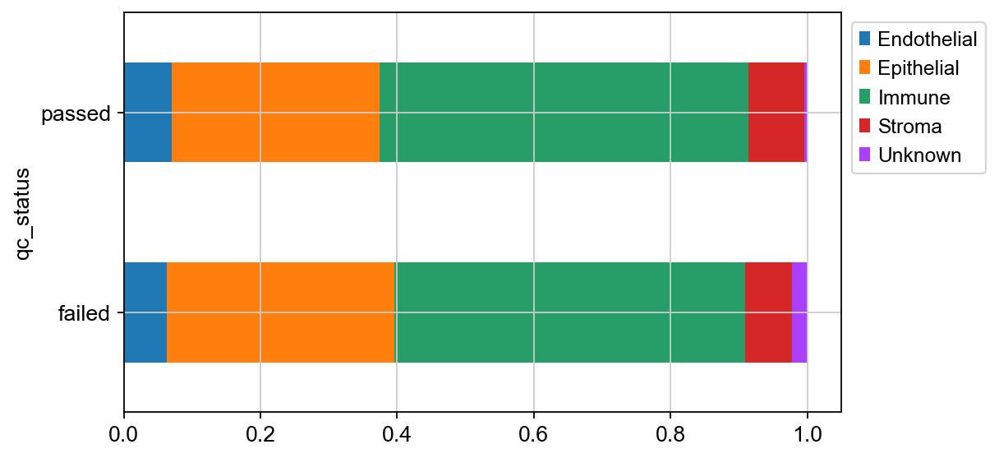

In [8]:
ax = pd.crosstab(
    adata.obs['qc_status'],
    adata.obs['ann_level_1'],
    normalize='index'
).plot(kind='barh', stacked=True, figsize=(7, 4))
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left')

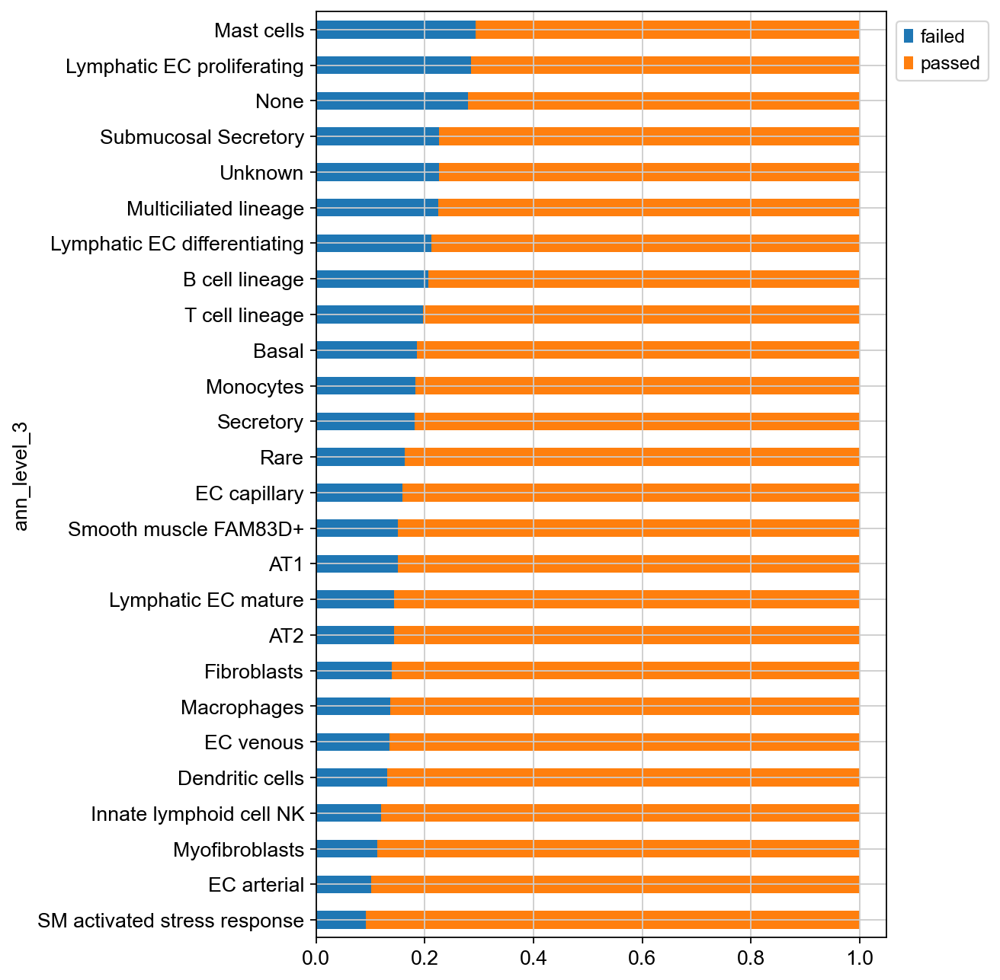

In [9]:
ax = pd.crosstab(
    adata.obs['ann_level_3'],
    adata.obs['qc_status'],
    normalize='index'
).sort_values(
    'failed',
    ascending=True
).plot(
    kind='barh',
    stacked=True,
    figsize=(6, 10),
)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left')

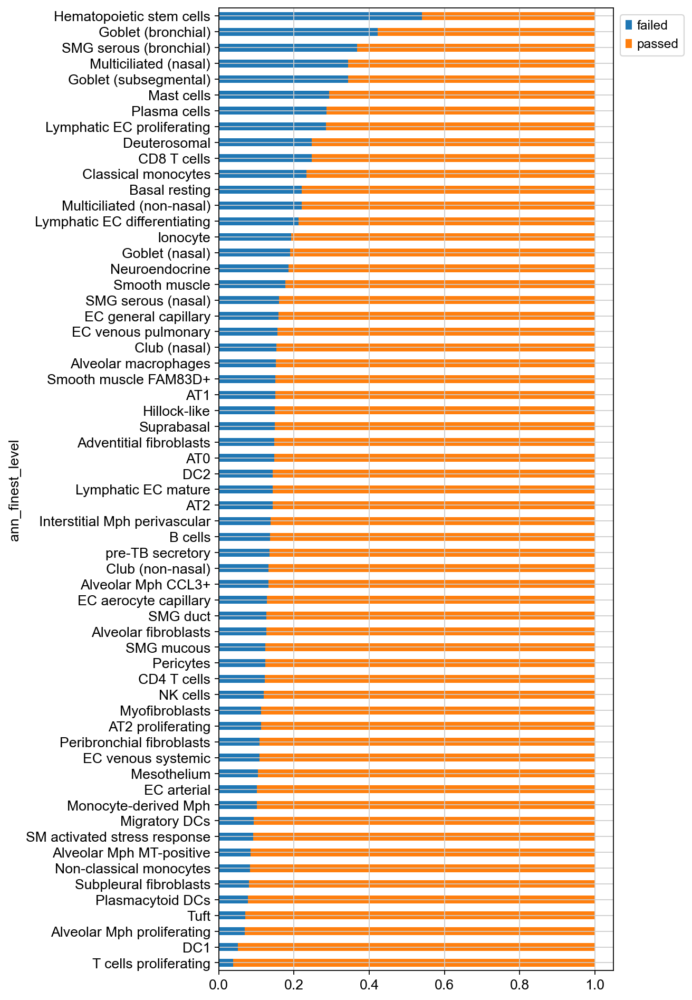

In [10]:
ax = pd.crosstab(
    adata.obs[ref_key],
    adata.obs['qc_status'],
    normalize='index'
).sort_values(
    'failed',
    ascending=True
).plot(
    kind='barh',
    stacked=True,
    figsize=(6, 15),
)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left')

## Marker gene overlap

In [11]:
import traceback
from marker_genes_functions import get_marker_genes

In [ ]:
n_genes = 50
marker_genes_HLCAv1 = get_marker_genes(
    adata,
    key='marker_genes_group=majority_reference--HLCAv1',
    n_genes=n_genes,
)

marker_genes_highqc = get_marker_genes(
    adata,
    key='marker_genes_group=majority_reference--highQC',
    n_genes=n_genes,
)

In [ ]:
from misc import run_similarity_analysis

In [ ]:
run_similarity_analysis(
    group_col='group',
    value_col='gene',
    df1=marker_genes_highqc,
    df1_label='High QC',
    df2=marker_genes_HLCAv1,
    df2_label='HLCAv1',
    title='Cell type marker gene overlap',
    figsize=(14, 14),
    cmap='viridis',
    lower_only=True,
    self_compare=True,
    cbar_name='Jaccard overlap',
)

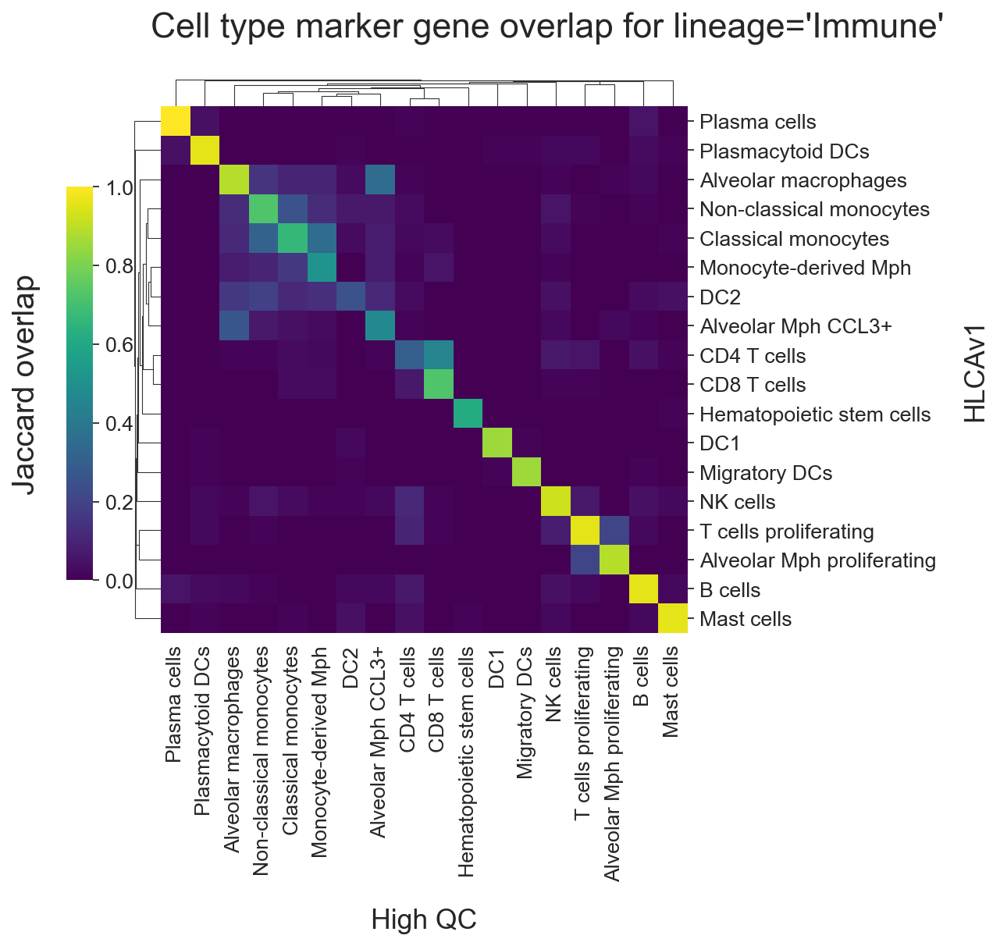

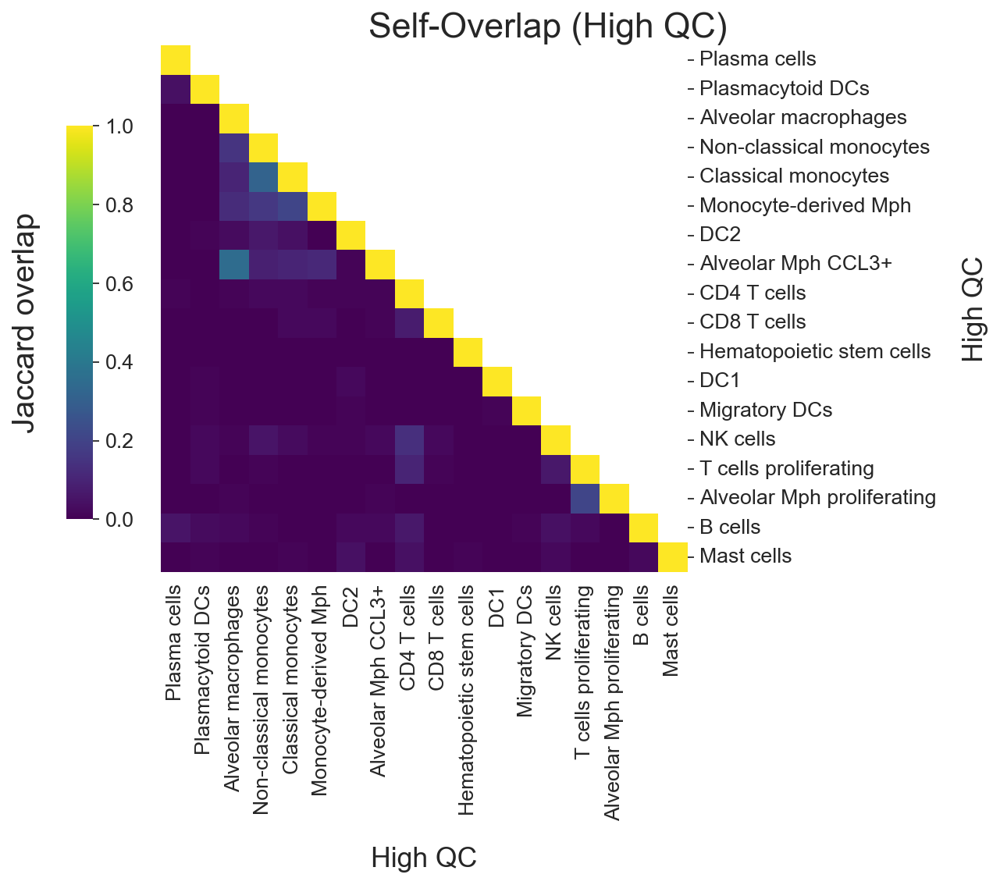

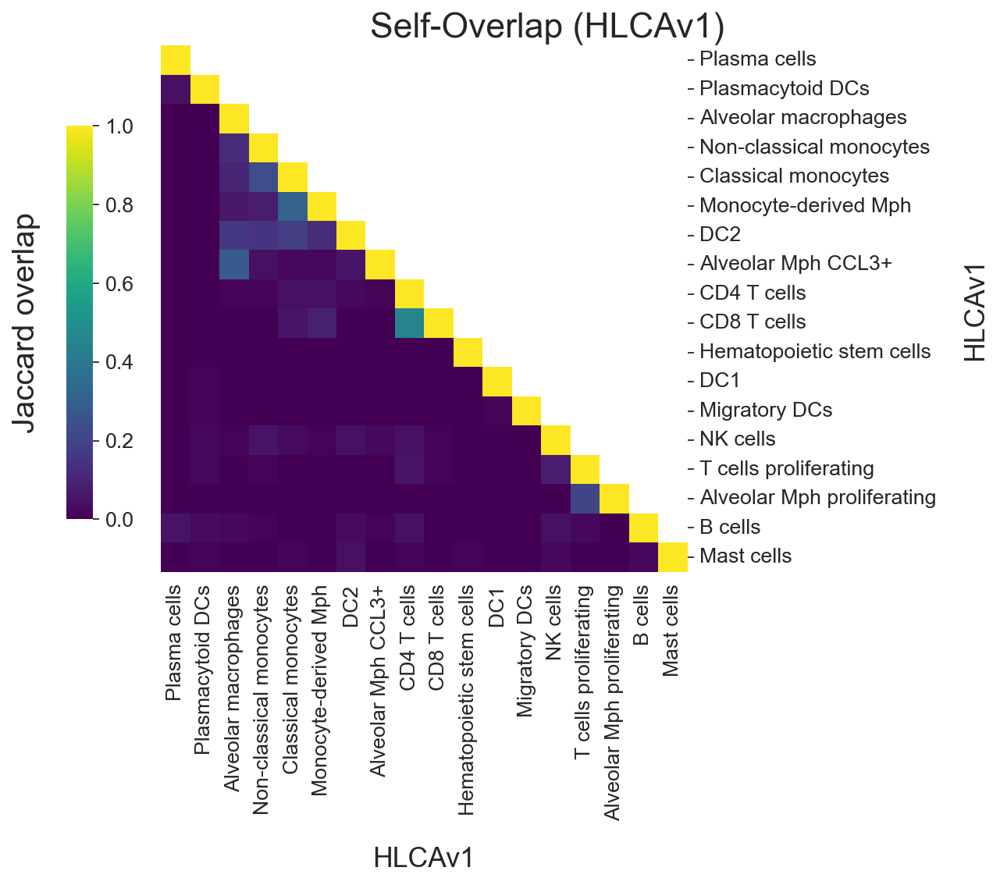

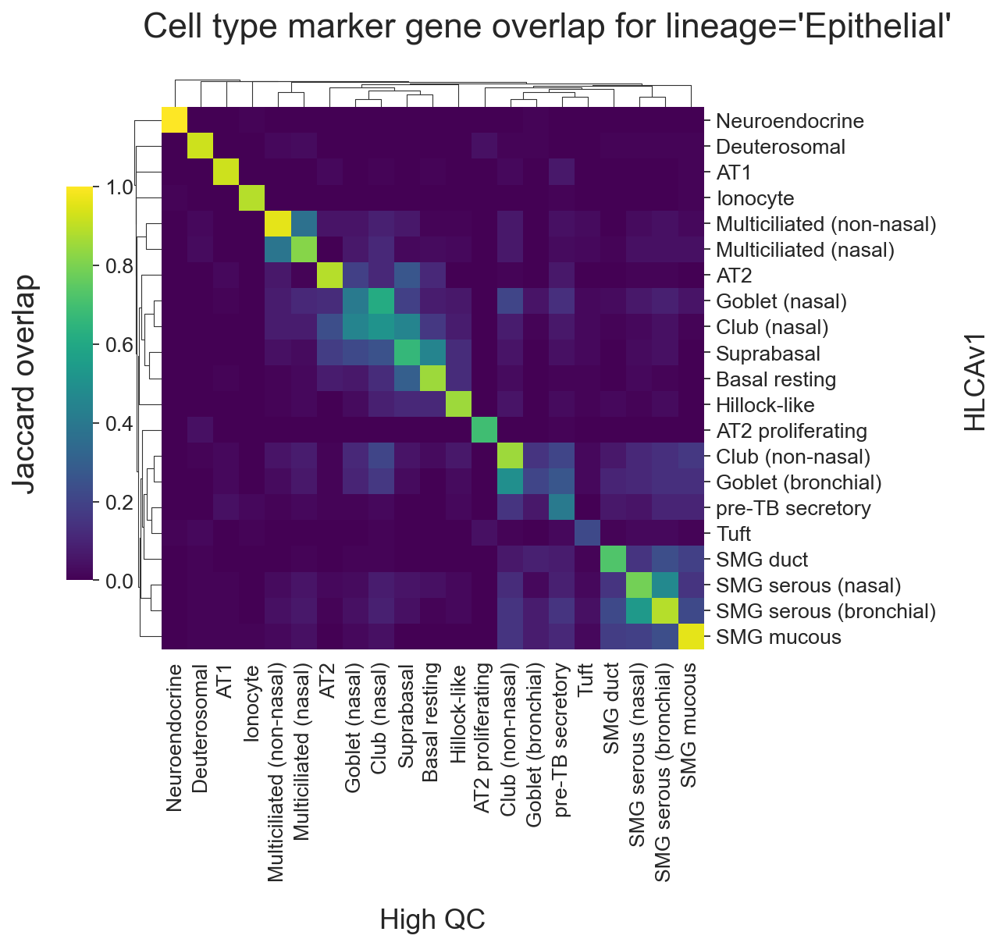

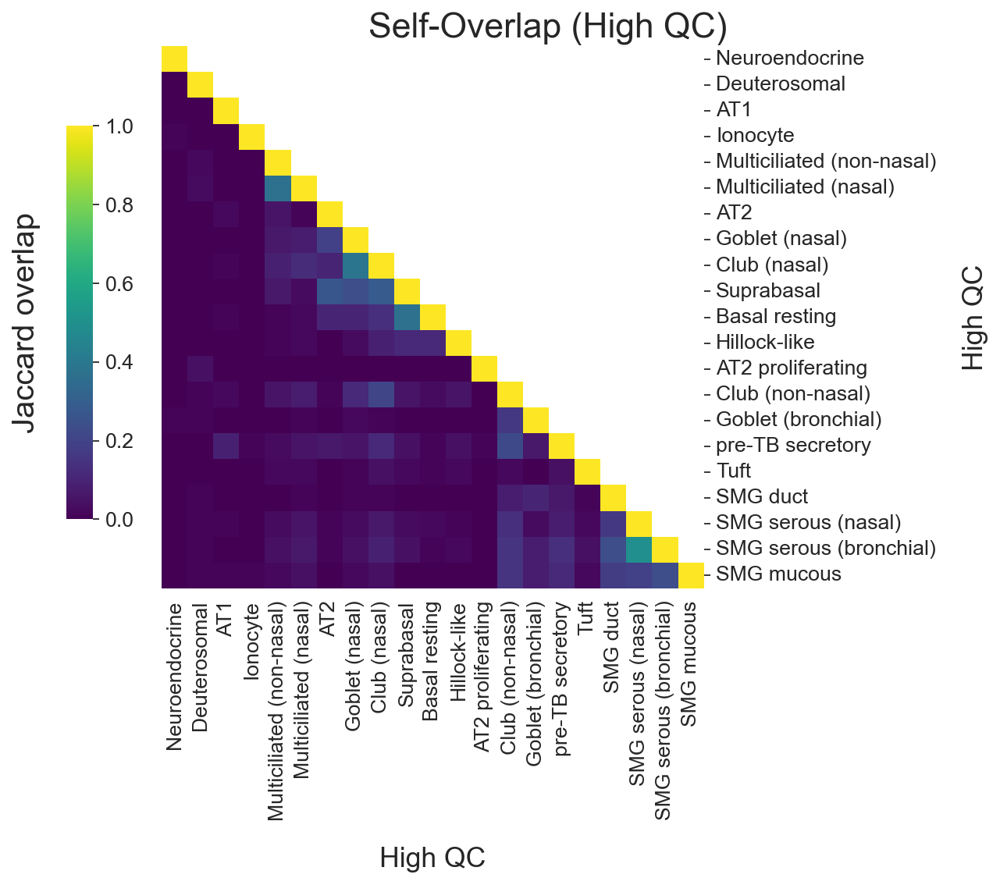

...

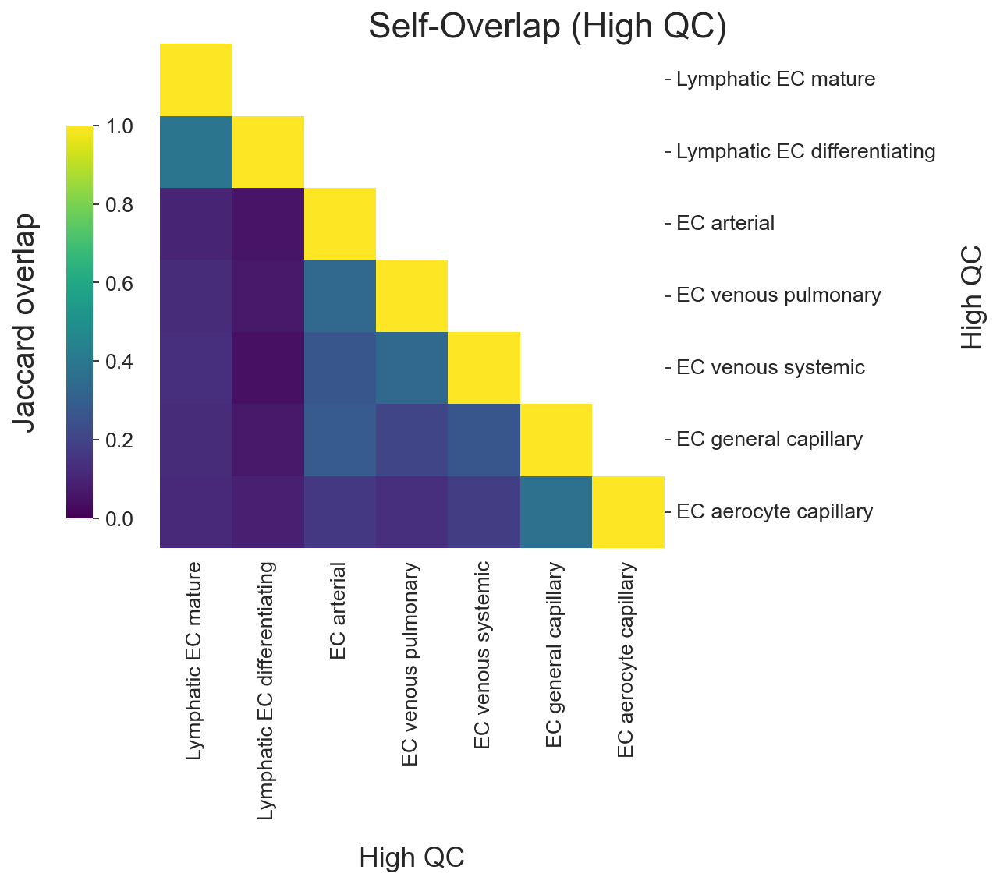

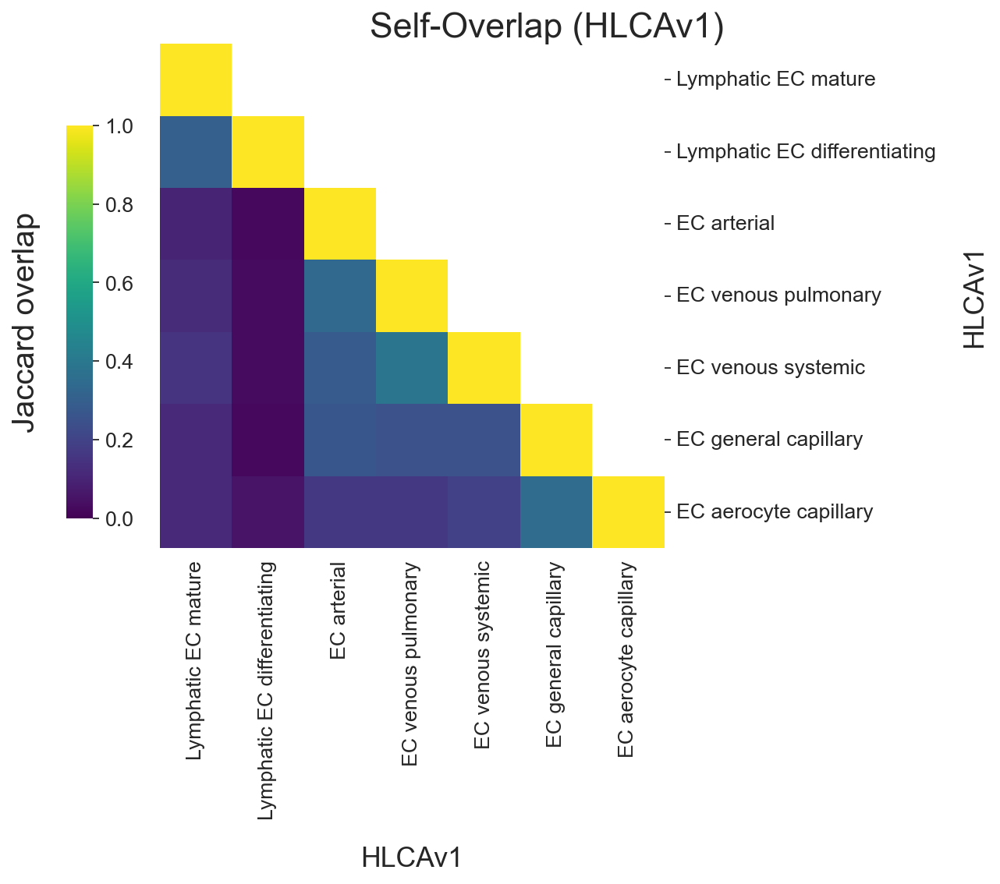

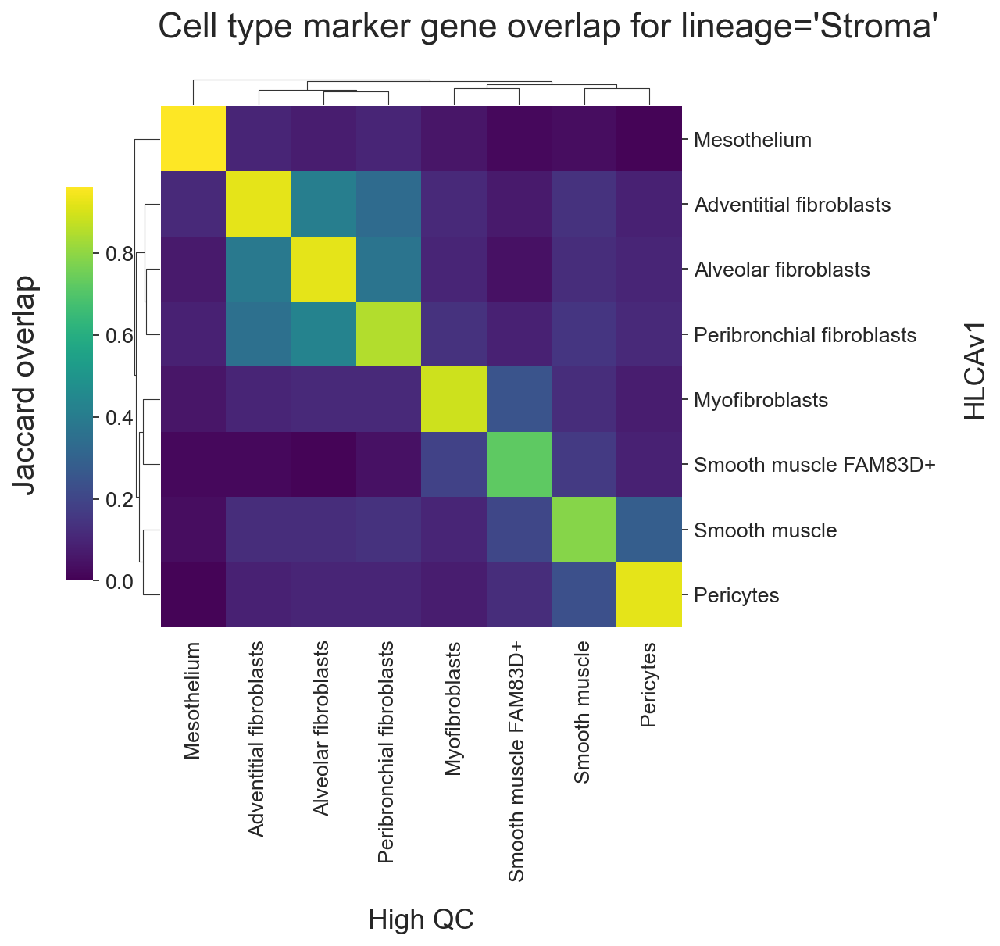

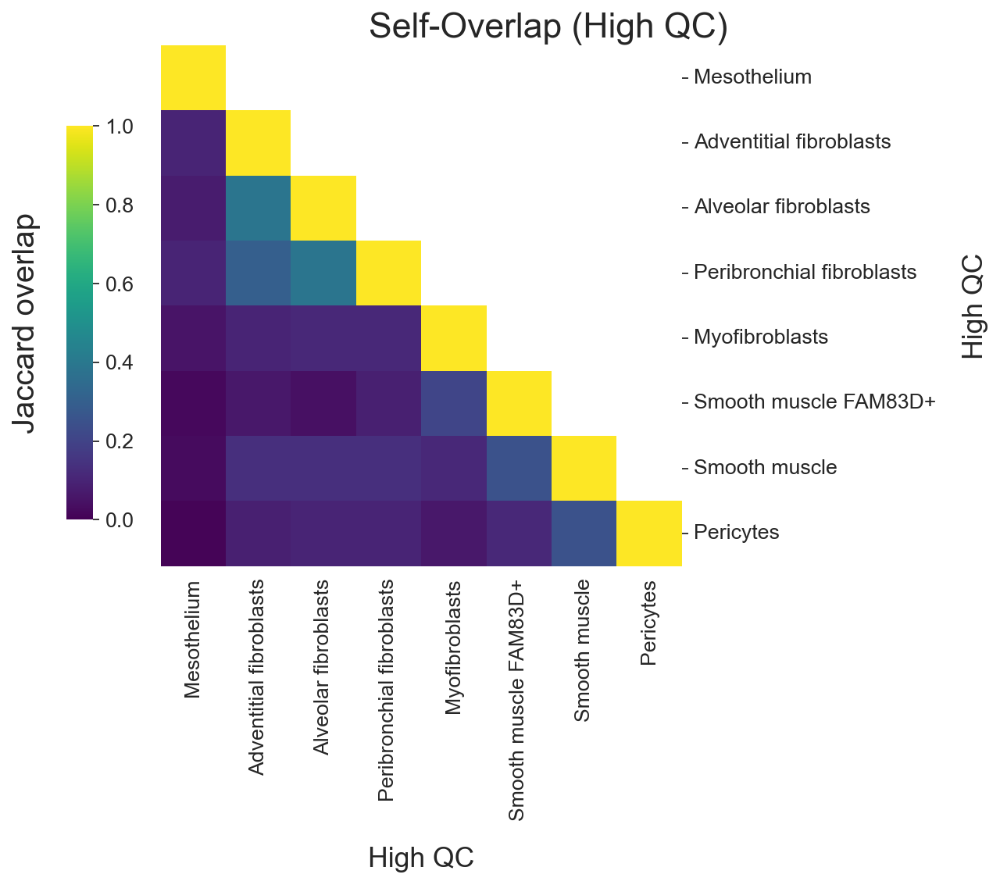

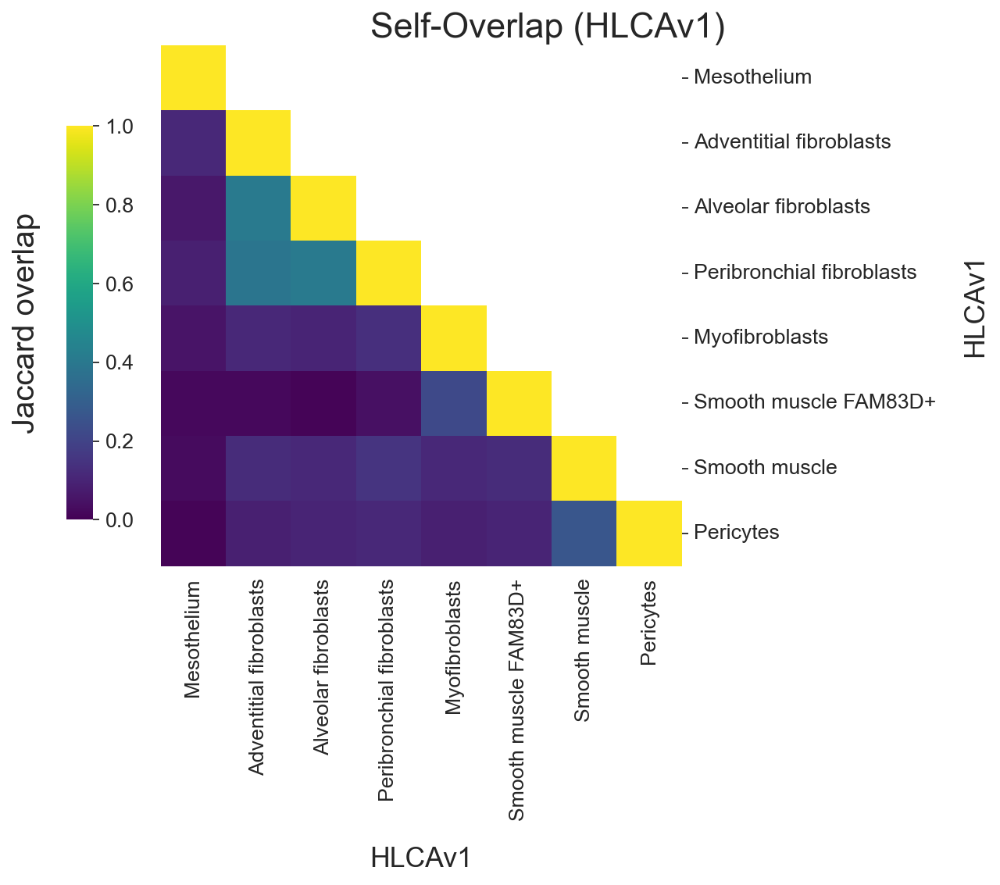

In [14]:
lineage_key = 'ann_level_1'
anno_map = adata.obs[[lineage_key, 'ann_finest_level']].value_counts()

for lineage in anno_map.index.get_level_values(lineage_key).unique():
    groups = anno_map.xs(key=lineage, level=lineage_key).index.values
    if len(groups) <= 1:
        print('not enough cell types per group, skipping...')
    try:
        _ = run_similarity_analysis(
            df1=marker_genes_highqc.query('group.isin(@groups)'),
            df1_label='High QC',
            df2=marker_genes_HLCAv1.query('group.isin(@groups)'),
            df2_label='HLCAv1',
            group_col='group',
            value_col='gene',
            cmap='viridis',
            title=f'Cell type marker gene overlap for {lineage=}',
            self_compare=True,
            figsize=(7,7),
            title_fontsize=20,
            cbar_name='Jaccard overlap',
        )
    except:
        print('skipping:', lineage)
        print(f'{groups=}')
        traceback.print_exc()

### Check overlap with curated marker genes

In [27]:
import yaml
from misc import back_to_back_barplot

In [28]:
with open('configs/HLCA/gene_sets_full.yaml', 'r') as f:
    marker_genes_dict = yaml.safe_load(f)

In [29]:
for gene_set in marker_genes_dict.values():
    for gene in gene_set:
        if gene not in adata.var['feature_name'].values:
            gene_set.remove(gene)

In [30]:
def get_frac_overlap(d1, d2):
    data = []
    for k in d1.keys() & d2.keys():
        s1, s2 = set(d1[k]), set(d2[k])
        data.append({
            'cell_type': k,
            'overlap': len(s1 & s2) / len(s1),
            'present': list(s1 & s2),
            'missing': list(s1 - s2)
        })

    return pd.DataFrame(data)

In [31]:
marker_overlap = pd.merge(
    get_frac_overlap(
        marker_genes_dict,
        marker_genes_highqc.groupby('group')['gene'].apply(list).to_dict(),
    ),
    get_frac_overlap(
        marker_genes_dict,
        marker_genes_HLCAv1.groupby('group')['gene'].apply(list).to_dict(),
    ),
    on='cell_type',
    suffixes=['_highQC', '_HLCAv1'],
).set_index('cell_type')

NameError: name 'marker_genes_highqc' is not defined

In [ ]:
marker_overlap['diff'] = marker_overlap['overlap_highQC'] - marker_overlap['overlap_HLCAv1']

In [ ]:
marker_genes_dict['CD4 T cells']

In [50]:
marker_overlap.query(
    'missing_highQC != missing_HLCAv1'
).sort_values('diff', ascending=False)

,overlap_highQC,present_highQC,missing_highQC,overlap_HLCAv1,present_HLCAv1,missing_HLCAv1,diff
cell_type,,,,,,,
pre-TB secretory,0.625000,"[ELF3, SFTPB, RNASE1, SFTA1P, EPCAM]","[IGFBP2, FXYD3, TSPAN1]",0.250000,"[SFTA1P, SFTPB]","[IGFBP2, RNASE1, FXYD3, ELF3, TSPAN1, EPCAM]",0.375000
Club (nasal),0.500000,"[FXYD3, ELF3, SERPINB3, TSPAN1]","[IGFBP2, ASRGL1, TCN1, EPCAM]",0.125000,[SERPINB3],"[IGFBP2, TCN1, ASRGL1, ELF3, FXYD3, TSPAN1, EP...",0.375000
Tuft,0.500000,"[ELF3, EPCAM]","[FXYD3, DAB1]",0.250000,[EPCAM],"[FXYD3, ELF3, DAB1]",0.250000
Lymphatic EC differentiating,0.888889,"[PROX1, MMRN1, FLT4, CCL21, SEMA3D, PKHD1L1, C...",[CLEC14A],0.666667,"[PROX1, MMRN1, FLT4, CCL21, SEMA3D, PKHD1L1]","[CLEC14A, CLDN5, TFF3]",0.222222
CD4 T cells,0.300000,"[CORO1A, ISG20, PTPRC]","[CD53, CD28, TRAT1, TNFRSF25, CD4, CD40LG, CCL5]",0.100000,[PTPRC],"[CD53, ISG20, CD28, TRAT1, TNFRSF25, CD4, CD40...",0.200000
Smooth muscle,0.500000,"[MFAP4, MYH11, TINAGL1]","[COL1A2, DCN, PLN]",0.333333,"[MYH11, TINAGL1]","[COL1A2, MFAP4, DCN, PLN]",0.166667
Alveolar Mph CCL3+,0.250000,"[FCER1G, CCL20]","[CD53, CLEC7A, PTPRC, C1orf162, CORO1A, FAM89A]",0.125000,[CCL20],"[CD53, CLEC7A, PTPRC, C1orf162, FCER1G, CORO1A...",0.125000
SMG serous (nasal),0.750000,"[FAM3D, TCN1, MUC7, FXYD3, ODAM, CCL28]","[ELF3, EPCAM]",0.625000,"[FAM3D, TCN1, FXYD3, ODAM, CCL28]","[MUC7, ELF3, EPCAM]",0.125000
Myofibroblasts,0.555556,"[MFAP4, LUM, TYRP1, LMOD1, DCN]","[COL6A3, ATP1B1, COL1A2, CFD]",0.444444,"[LMOD1, MFAP4, DCN, TYRP1]","[COL6A3, ATP1B1, COL1A2, CFD, LUM]",0.111111


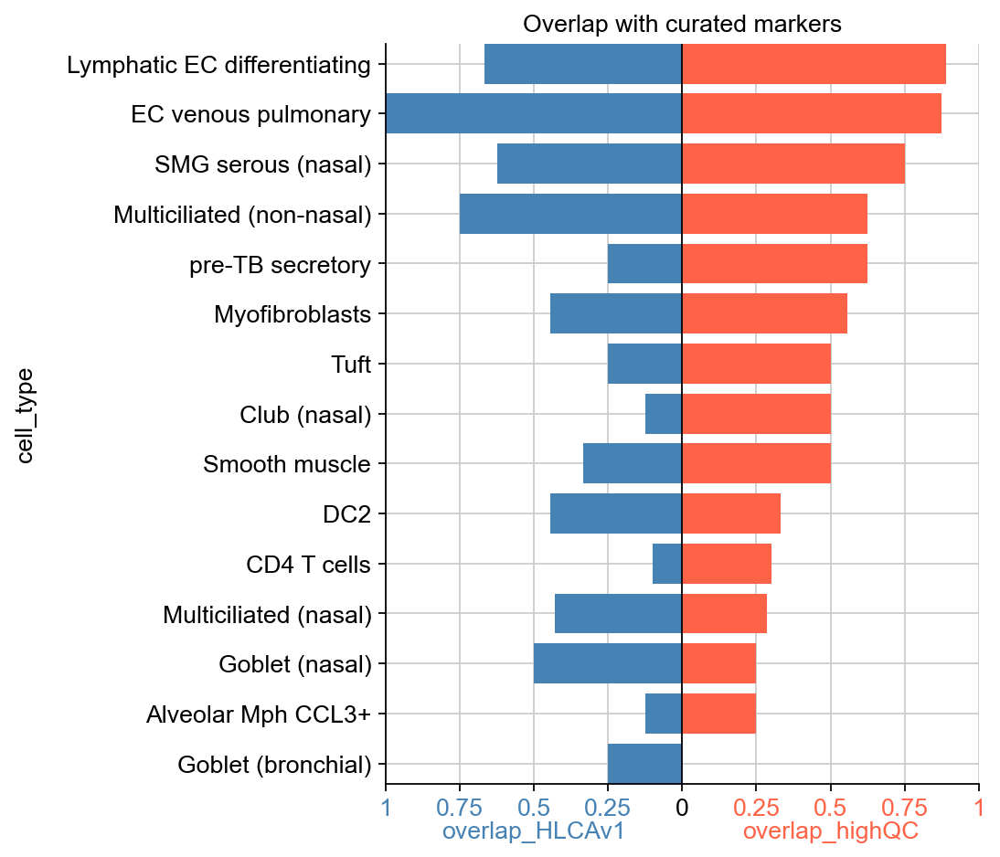

In [66]:
back_to_back_barplot(
    marker_overlap.query('missing_highQC != missing_HLCAv1').reset_index(),
    group_col='cell_type',
    left_col='overlap_HLCAv1',
    right_col='overlap_highQC',
    title='Overlap with curated markers',
    figsize=(7, 6),
    xlim_left=1,
    xlim_right=1,
)

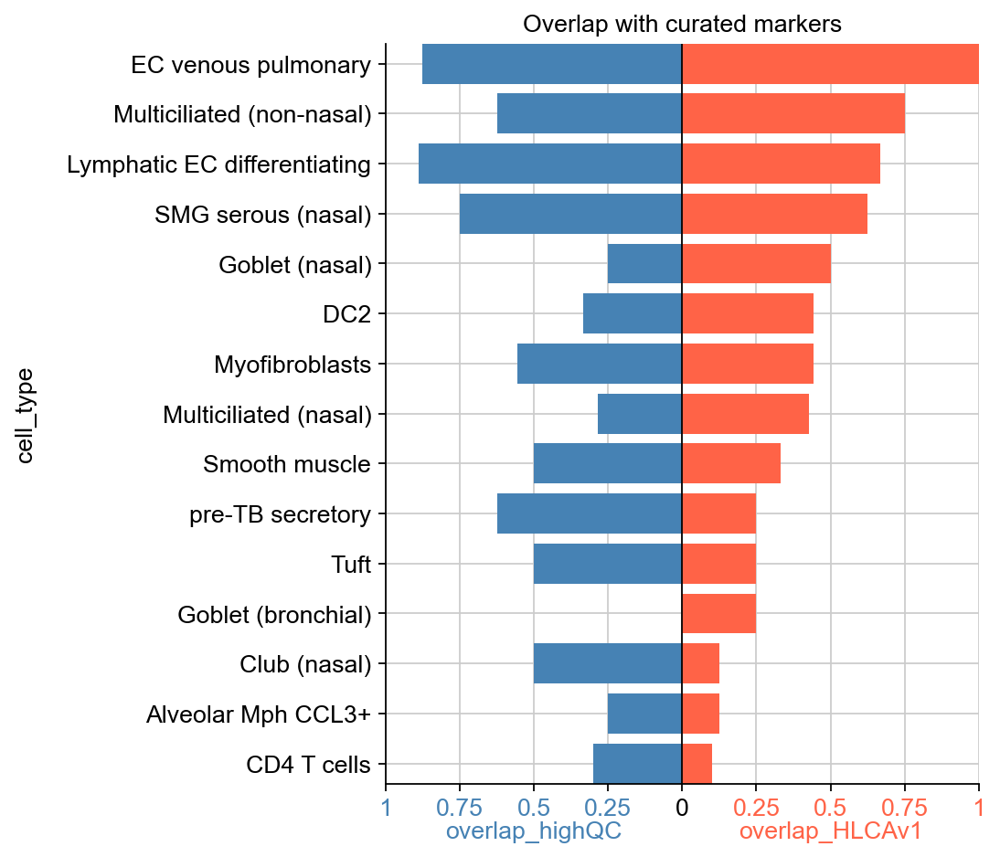

In [67]:
back_to_back_barplot(
    marker_overlap.query('missing_highQC != missing_HLCAv1').reset_index(),
    group_col='cell_type',
    left_col='overlap_highQC',
    right_col='overlap_HLCAv1',
    title='Overlap with curated markers',
    figsize=(7, 6),
    xlim_left=1,
    xlim_right=1,
)

## Doublet analysis

In [1]:
def plot_subcluster_umap(
    adata, group, mask, embeddings=['X_umap'], additional_colors=[],
    **kwargs,
):
    if mask.sum() == 0:
        raise ValueError('Empty mask')
    
    if 'group' in adata.obs.columns:
        del adata.obs['group']
    adata.obs.loc[mask, 'group'] = adata.obs.loc[mask, group].astype(str)
    
    for embedding in embeddings:
        print(embedding)
        sc.pl.embedding(
            adata,
            basis=embedding,
            color=additional_colors,
            plot_centroids=['group'],
            mask_obs=mask,
            **kwargs,
        )
        sc.pl.embedding(
            adata,
            basis=embedding,
            color=colors,
            plot_centroids=['group'],
            title=[f'{color} (reference only)' for color in colors],
            mask_obs=mask & highQC_reference,
            **kwargs,
        )
        sc.pl.embedding(
            adata,
            basis=embedding,
            color=additional_colors,
            plot_centroids=['group'],
            title=[f'{color} (extended only)' for color in colors],
            mask_obs=mask & extended_only_mask,
            **kwargs,
        )

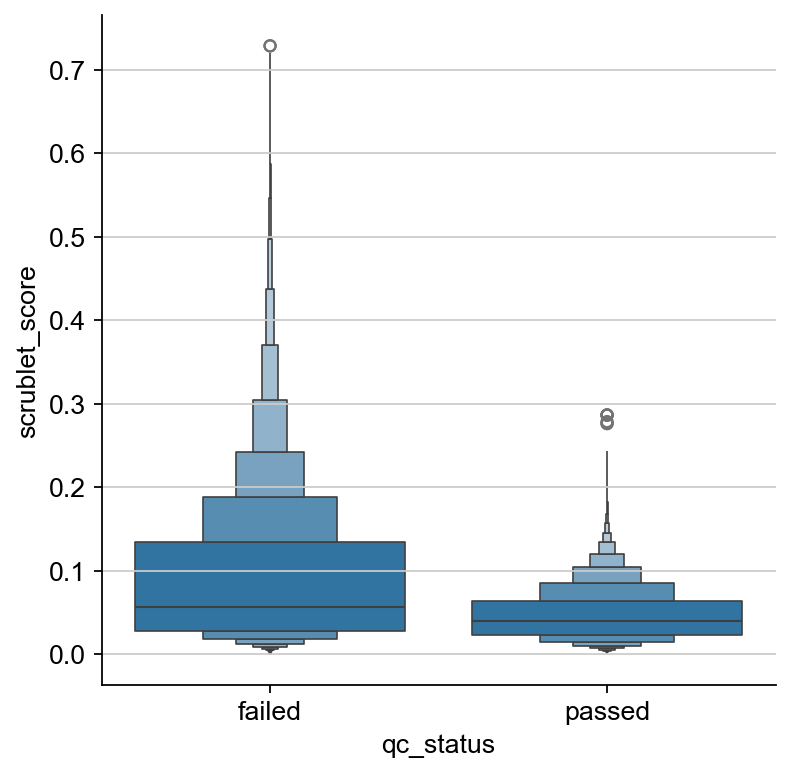

In [16]:
sns.catplot(
    data=adata.obs,
    x="qc_status",
    y="scrublet_score",
    kind='boxen',
)

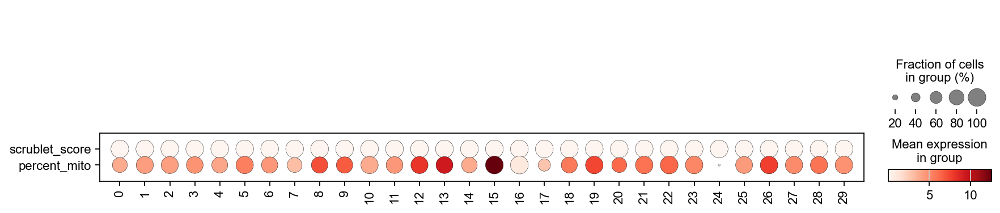

In [17]:
sc.pl.dotplot(
    adata,
    var_names=['scrublet_score', 'percent_mito'],
    groupby='leiden_0.5_1--highQC',
    swap_axes=True,
)

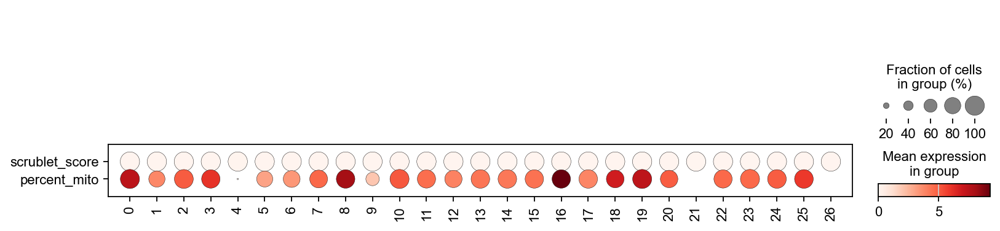

In [18]:
sc.pl.dotplot(
    adata,
    var_names=['scrublet_score', 'percent_mito'],
    groupby='leiden_0.5_1--HLCAv1',
    swap_axes=True,
)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


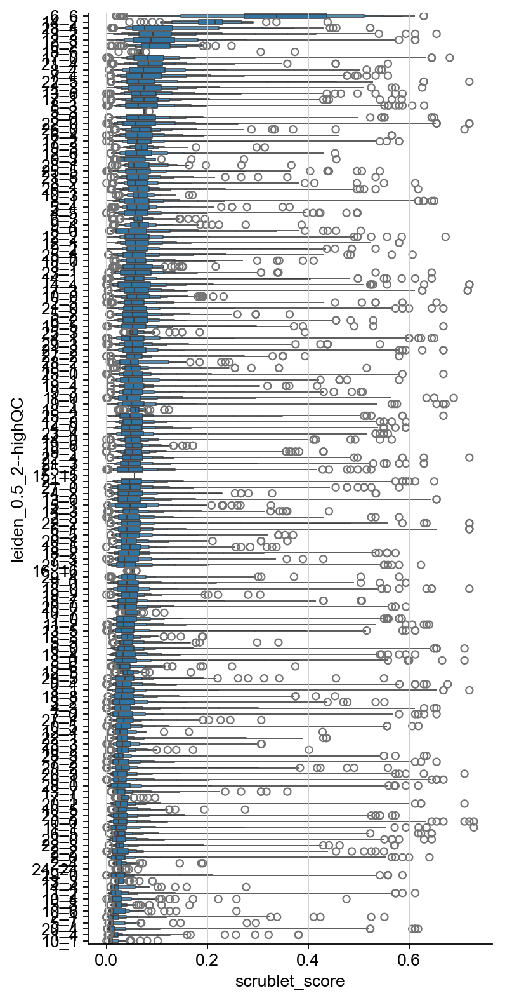

In [19]:
group = 'leiden_0.5_2--highQC'
value = "scrublet_score"

order = (
    adata.obs.groupby(group, observed=True)[value]
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.catplot(
    data=adata.obs,
    x=value,
    y=group,
    order=order,
    kind='boxen',
    height=10,
    aspect=0.5,
)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


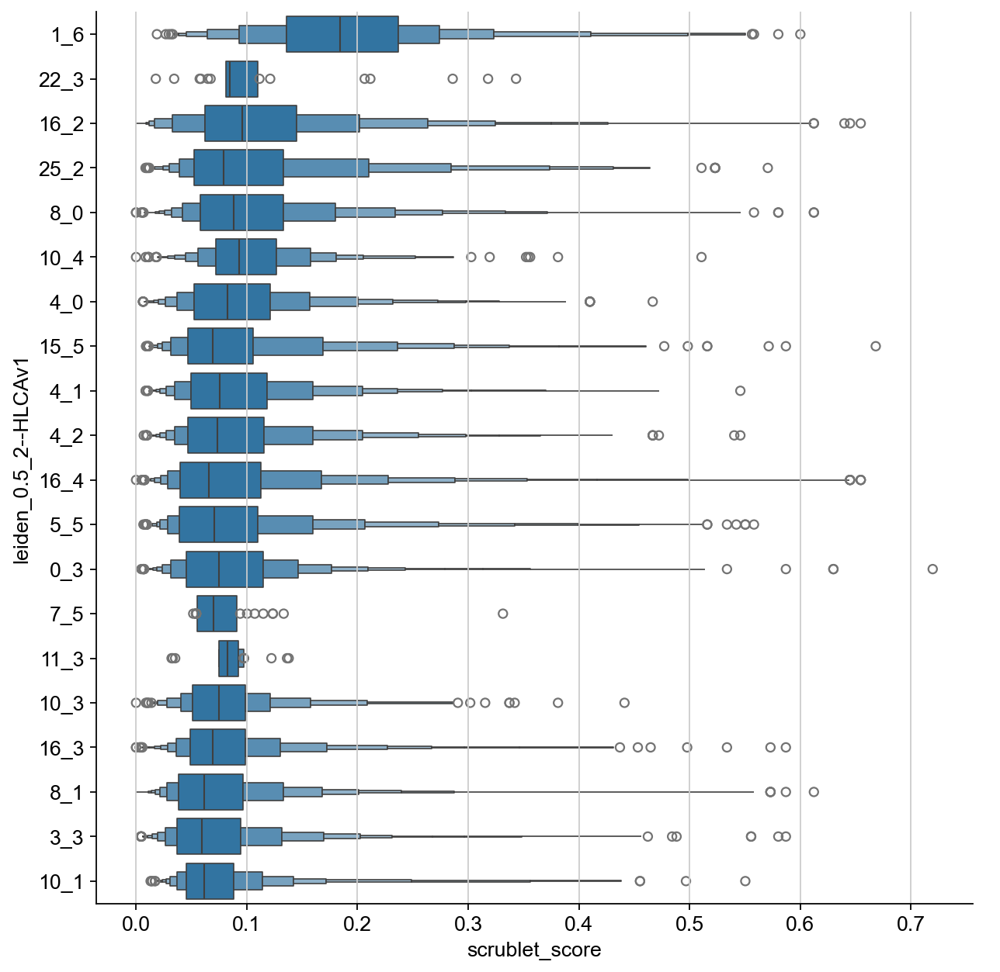

In [20]:
group = 'leiden_0.5_2--HLCAv1'
value = "scrublet_score"
    
order = (
    adata.obs.groupby(group, observed=True)[value]
    .mean()
    .sort_values(ascending=False)
    .nlargest(20)
    .index
)

sns.catplot(
    data=adata.obs.query(f'`{group}`.isin(@order)'),
    x=value,
    y=group,
    order=order,
    kind='boxen',
    height=8,
    aspect=1,
)

INFO:scatlastb_utils.pl.embedding:Configured colors:
['scrublet_score', 'group']
INFO:scatlastb_utils.pl.embedding:Colors from obs after filtering:
['scrublet_score', 'group']
INFO:scatlastb_utils.pl.embedding:Convert view to copy...


X_umap--HLCAv1


INFO:scatlastb_utils.pl.embedding:Remove outliers...
INFO:scatlastb_utils.pl.embedding:Parameters:
{'mask_obs': CGATGTAAGTTACGGG_SC10                          False
cc05p_CATGCCTGTGTGCCTG_carraro_csmc            False
ATTCTACCAAGGTTCT_HD68                          False
D062_TGACCCTTCAAACCCA-sub_wang_sub_batch3      False
muc9826_GTCGTGAGAGGA_mayr                      False
                                               ...  
TTGTGGATCGTTCCTG_5-PX5-sub_mould               False
TCAGGATCAAGACGTG_F02526                        False
CAACCTCTCATGTAGC-WSSS8015042-0_meyer_unpubl    False
022C-b_GGATGTTTCCAAGTAC_adams                  False
145I-a_GTCGTAACAGTAGAGC_adams                  False
Name: leiden_0.5_2--HLCAv1, Length: 2282447, dtype: bool,
 'palette': ['#1f77b4',
             '#ff7f0e',
             '#279e68',
             '#d62728',
             '#aa40fc',
             '#8c564b',
             '#e377c2',
             '#b5bd61',
             '#17becf',
             '#aec7e8',
       

TypeError: scanpy.plotting._tools.scatterplots.embedding() got multiple values for keyword argument 'palette'

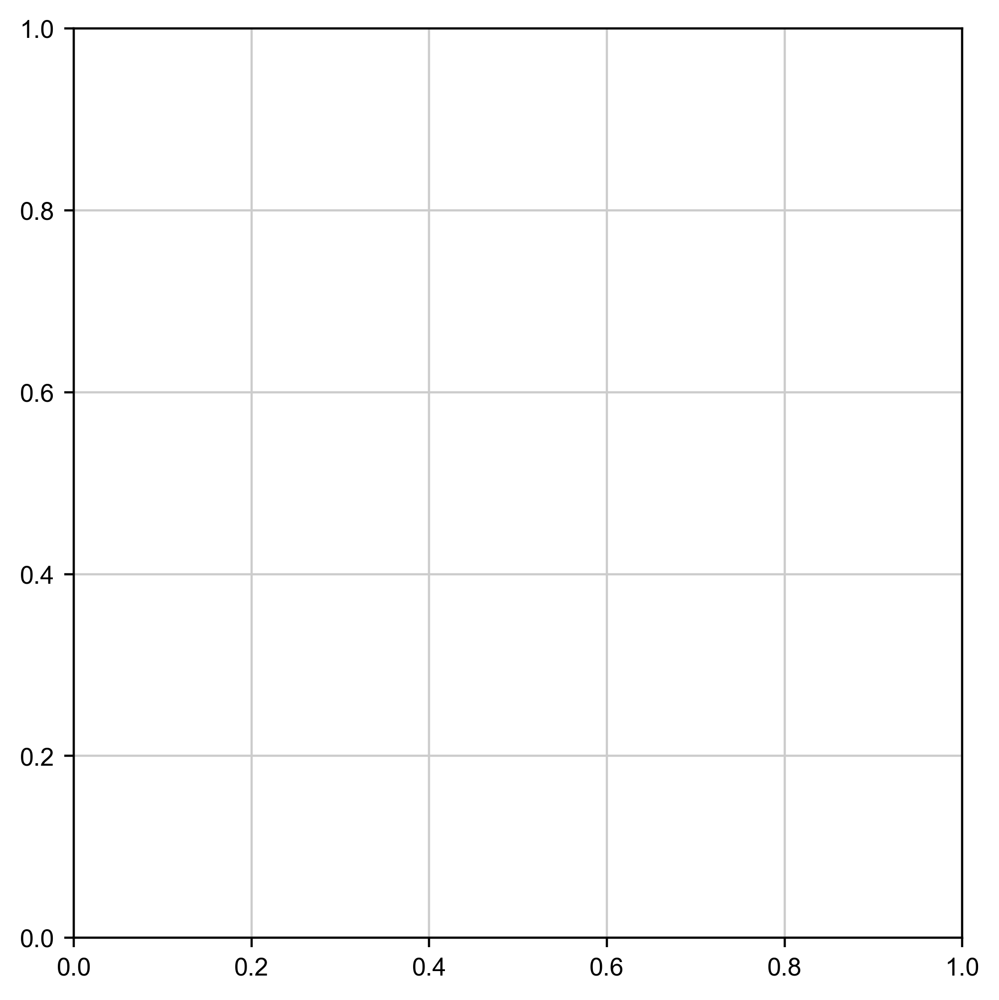

In [21]:
plot_subcluster_umap(
    adata,
    group=group,
    mask=adata.obs[group].isin(order[:10]),
    size=5,
    # palette=sc.pl.palettes.default_20,
    additional_colors=['scrublet_score'],
    embeddings=['X_umap--HLCAv1', 'X_umap--highQC'],
)

In [ ]:
group = 'leiden_0.5_2--highQC'
value = "scrublet_score"
    
order = (
    adata.obs.groupby(group, observed=True)[value]
    .mean()
    .sort_values(ascending=False)
    .nlargest(20)
    .index
)

sns.catplot(
    data=adata.obs.query(f'`{group}`.isin(@order)'),
    x=value,
    y=group,
    order=order,
    kind='boxen',
    height=8,
    aspect=1,
)

In [ ]:
plot_subcluster_umap(
    adata,
    group=group,
    mask=adata.obs[group].isin(order[:1]),
    size=5,
    palette=sc.pl.palettes.default_20,
    additional_colors=['scrublet_score'],
    embeddings=['X_umap--HLCAv1', 'X_umap--highQC'],
)

## Graph dissimilarity

In [10]:
import scatlastb_utils as atl

In [11]:
integration1, integration2 = integrations

In [12]:
tqdm._instances.clear()

In [13]:
%%time
comp = f'{integration1}-vs-{integration2}'

adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = atl.metrics.compare_distances(
    adata,
    obsp_connectivities_1=f'connectivities--{integration1}',
    obsp_distances_1=f'distances--{integration1}',
    obsm_key_1=f'X_emb--{integration1}',
    obsp_connectivities_2=f'connectivities--{integration2}',
    obsp_distances_2=f'distances--{integration2}',
    obsm_key_2=f'X_emb--{integration2}',
    scale_distances=True,
    log_scale_diffs=False,
    n_jobs=5,
)

comp = f'{integration2}-vs-{integration1}'
adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = atl.metrics.compare_distances(
    adata,
    obsp_connectivities_1=f'connectivities--{integration2}',
    obsp_distances_1=f'distances--{integration2}',
    obsm_key_1=f'X_emb--{integration2}',
    obsp_connectivities_2=f'connectivities--{integration1}',
    obsp_distances_2=f'distances--{integration1}',
    obsm_key_2=f'X_emb--{integration1}',
    scale_distances=True,
    log_scale_diffs=False,
    n_jobs=5,
)

43543599 edges to recompute


scale distances by 0.9 quantile...
Calculate differences...
43461125 edges to recompute


scale distances by 0.9 quantile...
Calculate differences...
CPU times: user 2min 43s, sys: 15.8 s, total: 2min 59s
Wall time: 2min 49s


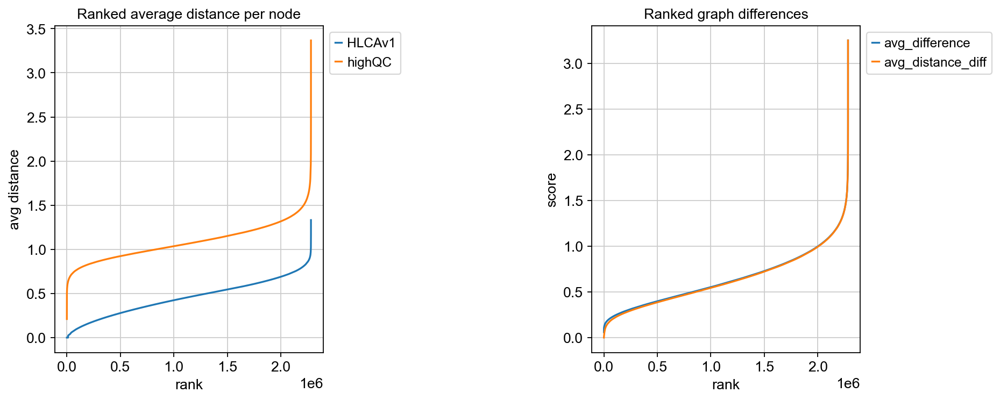

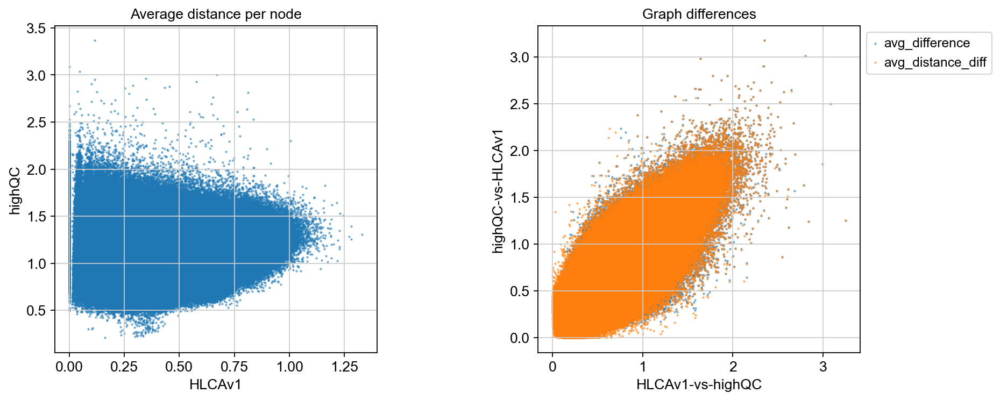

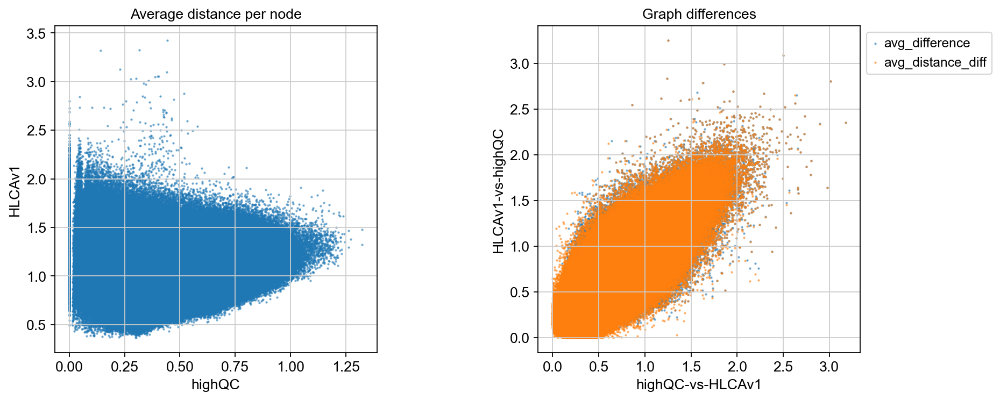

In [14]:
atl.me.plot_ranked_distances(adata, integration1, integration2)
atl.me.plot_distances_scatter(adata, integration1, integration2, s=1, alpha=0.5)
atl.me.plot_distances_scatter(adata, integration2, integration1, s=1, alpha=0.5)

In [15]:
def plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric,
    max_quantile=None,
    **kwargs,
):
    comparisons = [
        f'{integration1}-vs-{integration2}',
        f'{integration2}-vs-{integration1}'
    ]
    colors = [f'{metric}:{comparison}' for comparison in comparisons]
    ncols = len(comparisons)
    
    if max_quantile:
        kwargs['vmax'] = adata.obs[colors].quantile(max_quantile).tolist()
    
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=colors,
        ncols=ncols,
        wspace=0.2,
        **kwargs,
    )
 
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=colors,
        ncols=ncols,
        wspace=0.2,
        **kwargs,
    )

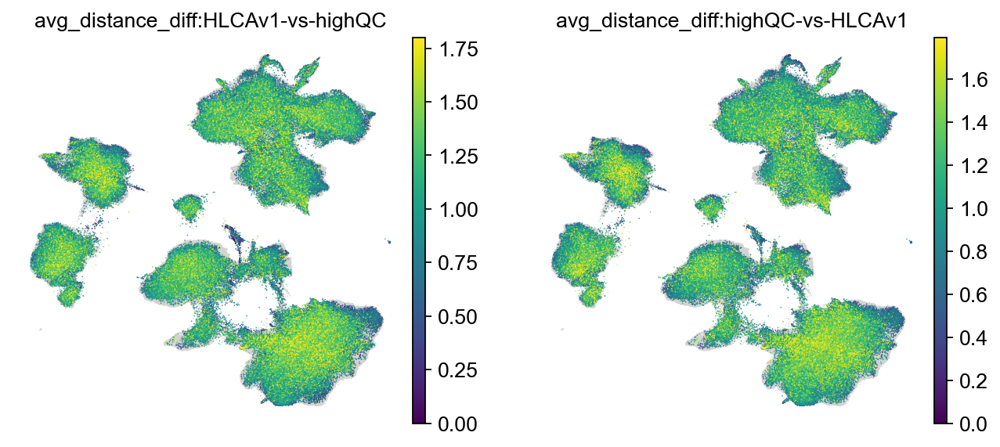

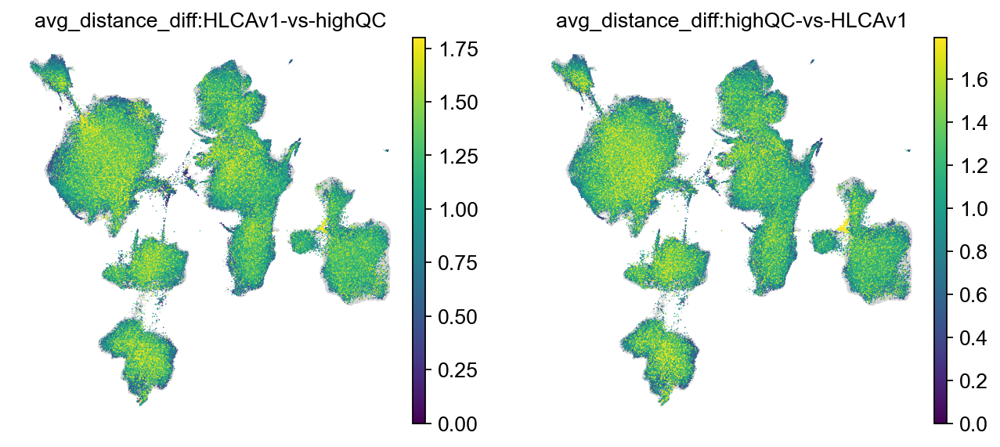

In [16]:
plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric='avg_distance_diff',
    cmap='viridis',
    size=2,
    vmin=0,
    max_quantile=0.999,
    mask_obs=adata.obs.eval('qc_status == "failed"')
)

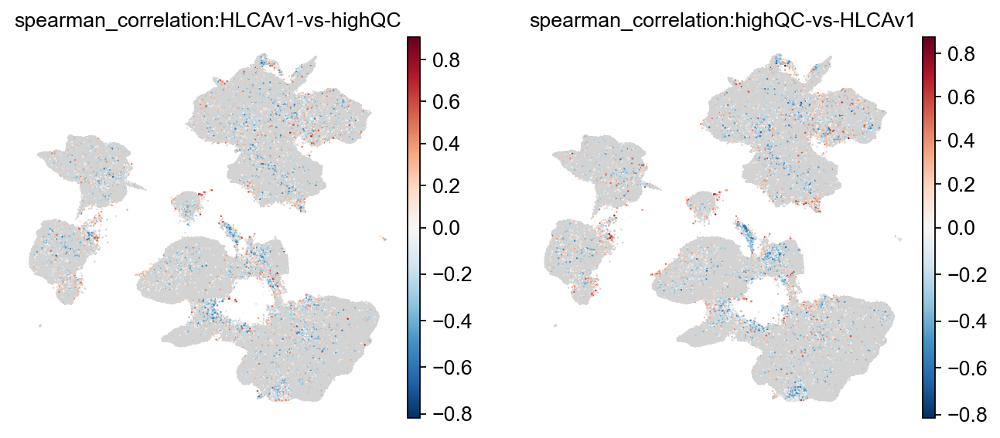

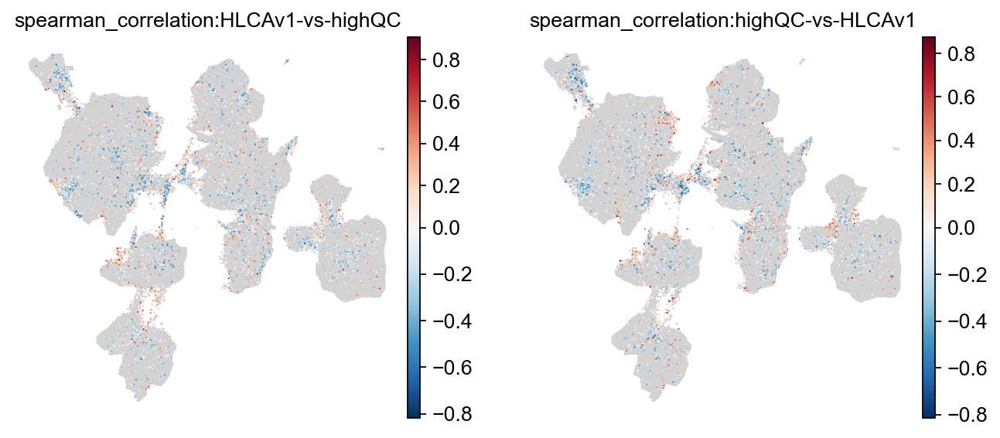

In [17]:
plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric='spearman_correlation',
    size=5,
    cmap="RdBu_r",
    sort_order=False,
    vcenter=0,
    mask_obs=adata.obs.eval('qc_status == "failed"')
)

### Explore top differential clusters

<Axes: xlabel='qc_status', ylabel='avg_distance_diff:highQC-vs-HLCAv1'>

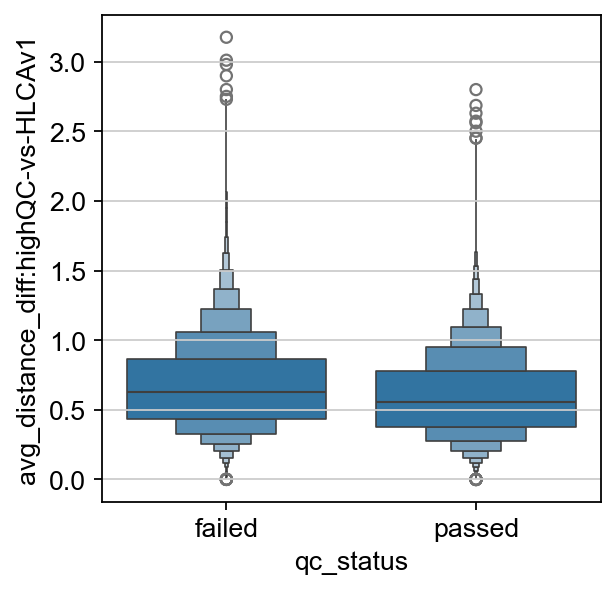

In [19]:
sns.boxenplot(
    data=adata.obs,
    x='qc_status',
    y='avg_distance_diff:highQC-vs-HLCAv1',
)

# TODO: per cell type

In [ ]:
sns.stripplot(
    data=adata.obs,
    x='qc_status',
    y='spearman_correlation:highQC-vs-HLCAv1',
)

In [21]:
from misc import plot_diff_per_clusters

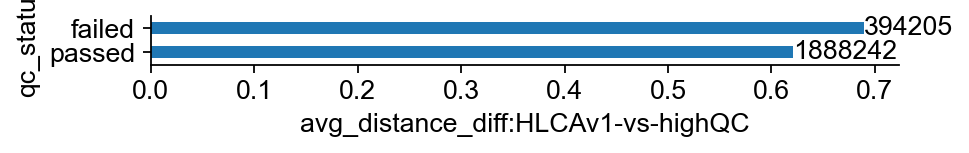

qc_status
passed    0.620970
failed    0.689311
Name: avg_distance_diff:HLCAv1-vs-highQC, dtype: float64

In [22]:
plot_diff_per_clusters(
    adata,
    'qc_status',
    f'avg_distance_diff:{integration1}-vs-{integration2}',
)

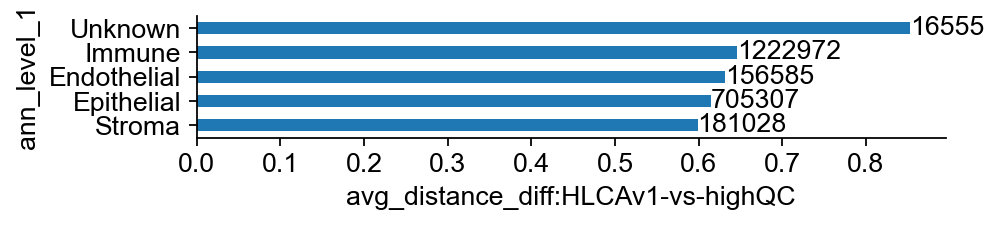

ann_level_1
Stroma         0.598766
Epithelial     0.614328
Endothelial    0.632137
Immune         0.645548
Unknown        0.852781
Name: avg_distance_diff:HLCAv1-vs-highQC, dtype: float64

In [23]:
plot_diff_per_clusters(
    adata,
    'ann_level_1',
    f'avg_distance_diff:{integration1}-vs-{integration2}',
)

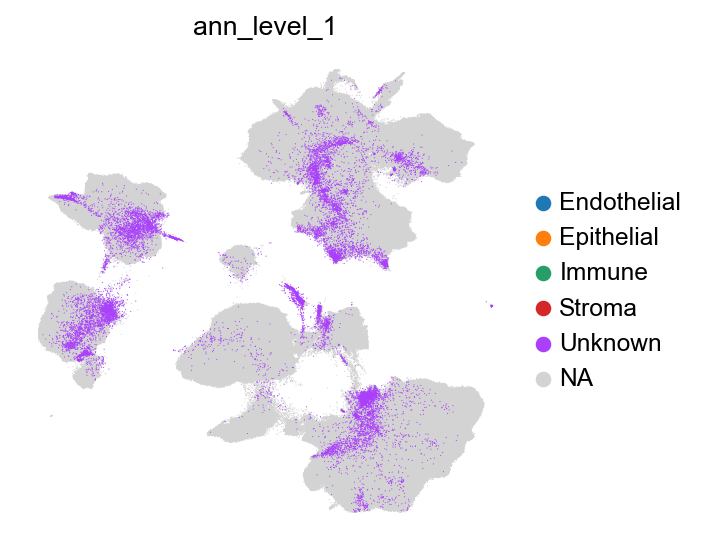

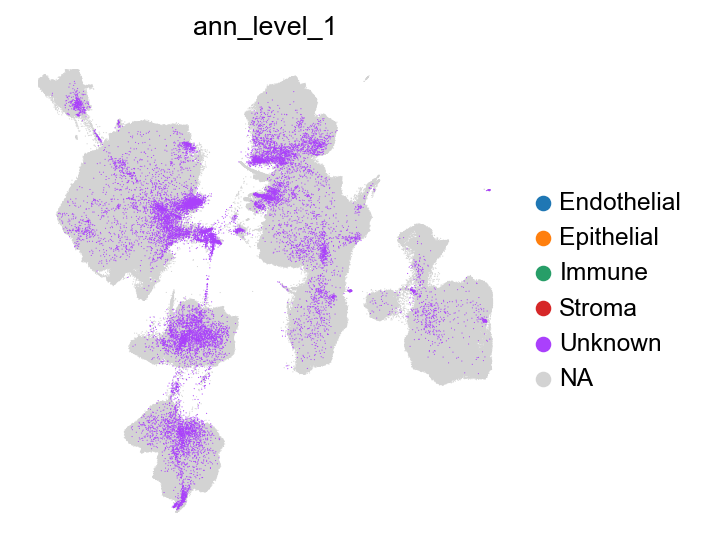

In [24]:
color = 'ann_level_1'
mask = adata.obs[color] == 'Unknown'
sc.pl.embedding(
    adata,
    basis='X_umap--HLCAv1',
    color=color,
    mask_obs=mask,
    size=1,
)

sc.pl.embedding(
    adata,
    basis='X_umap--highQC',
    color=color,
    mask_obs=mask,
    size=1,
)

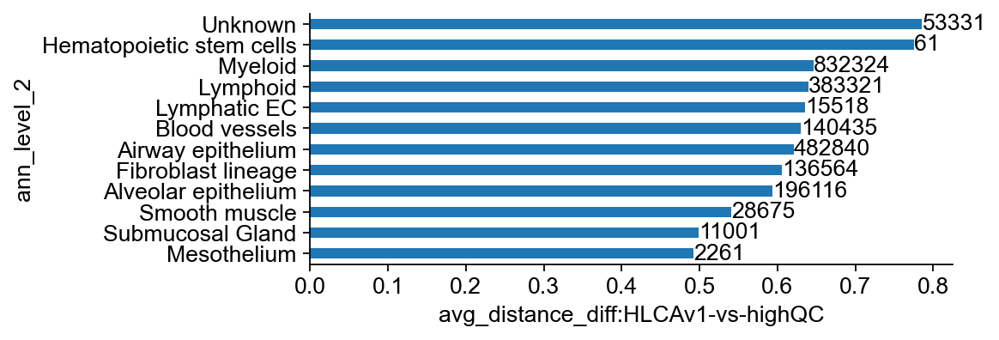

ann_level_2
Mesothelium                 0.492512
Submucosal Gland            0.499000
Smooth muscle               0.540884
Alveolar epithelium         0.593257
Fibroblast lineage          0.605533
Airway epithelium           0.620652
Blood vessels               0.630296
Lymphatic EC                0.635470
Lymphoid                    0.639615
Myeloid                     0.646294
Hematopoietic stem cells    0.774950
Unknown                     0.785899
Name: avg_distance_diff:HLCAv1-vs-highQC, dtype: float64

In [25]:
plot_diff_per_clusters(
    adata,
    'ann_level_2',
    f'avg_distance_diff:{integration1}-vs-{integration2}',
)

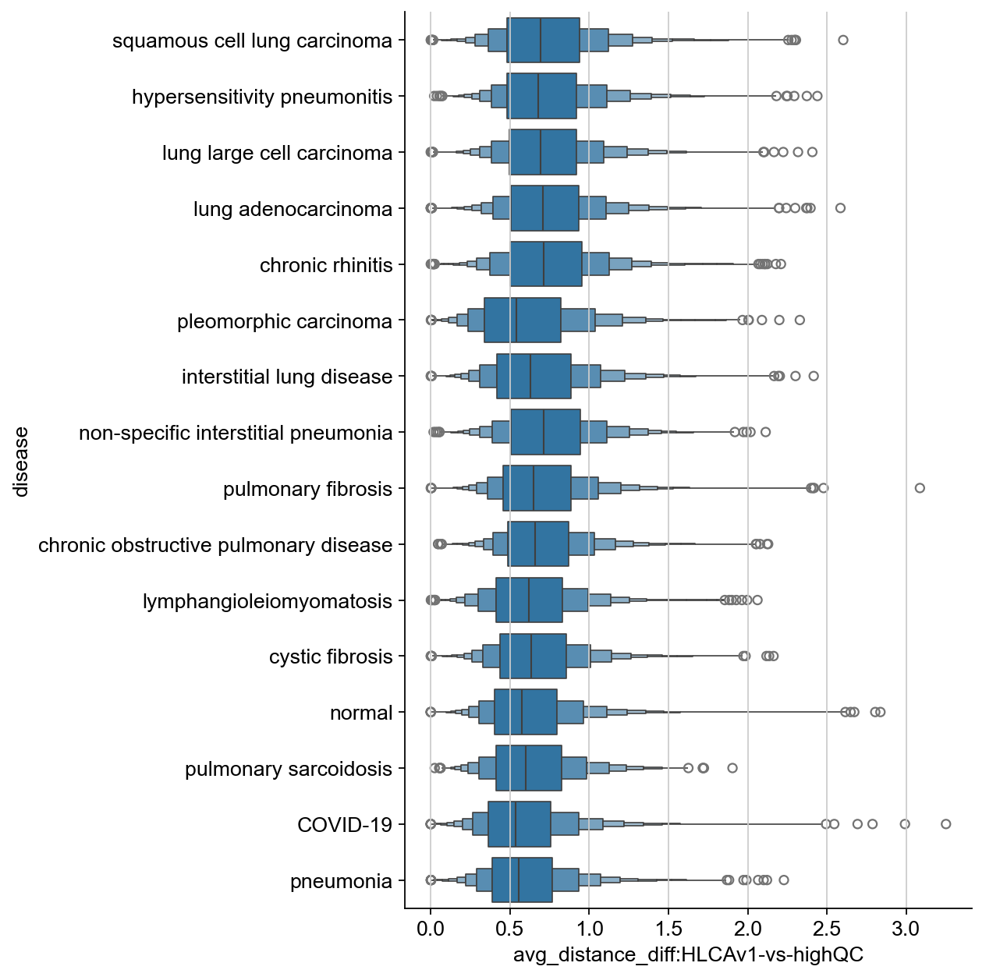

In [26]:
sns.catplot(
    adata.obs,
    y="disease",
    x=f"avg_distance_diff:{integration1}-vs-{integration2}",
    kind="boxen",
    aspect=1,
    height=8,
    order=adata.obs
        .groupby(
            "disease",
            observed=True,
        )[f"avg_distance_diff:{integration1}-vs-{integration2}"]
        .quantile(0.99)
        .sort_values(ascending=False)
        .index
)

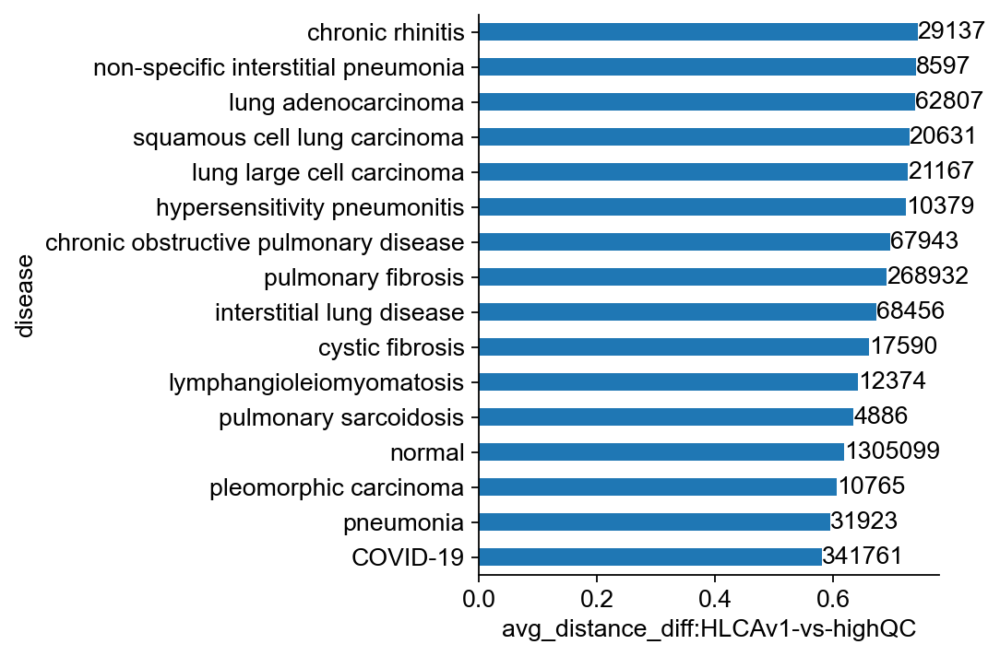

In [27]:
disease_rank = plot_diff_per_clusters(
    adata,
    'disease',
    f'avg_distance_diff:{integration1}-vs-{integration2}',
    figsize=(4, 5),
)

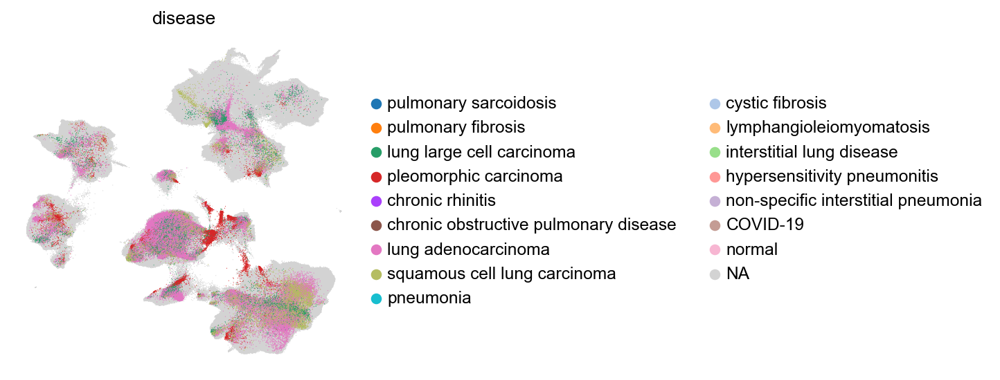

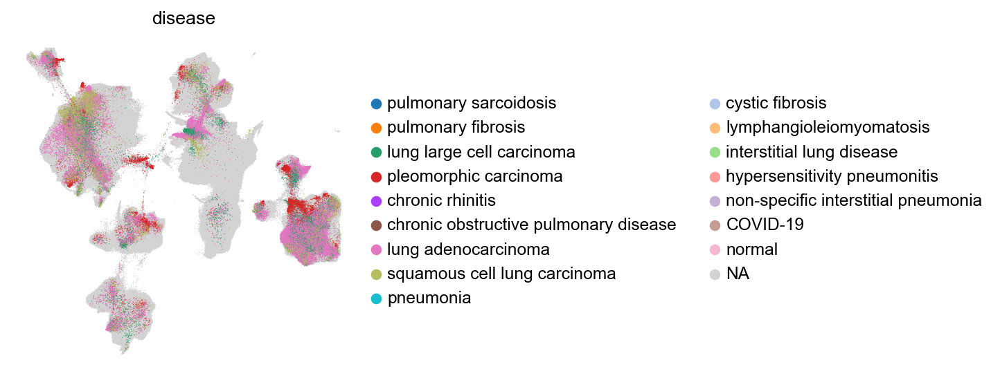

In [28]:
color = 'disease'
mask = adata.obs[color] != 'normal'
mask = adata.obs[color].str.contains('carcinoma')
sc.pl.embedding(
    adata,
    basis='X_umap--HLCAv1',
    color=color,
    mask_obs=mask,
    size=1,
)

sc.pl.embedding(
    adata,
    basis='X_umap--highQC',
    color=color,
    mask_obs=mask,
    size=1,
)

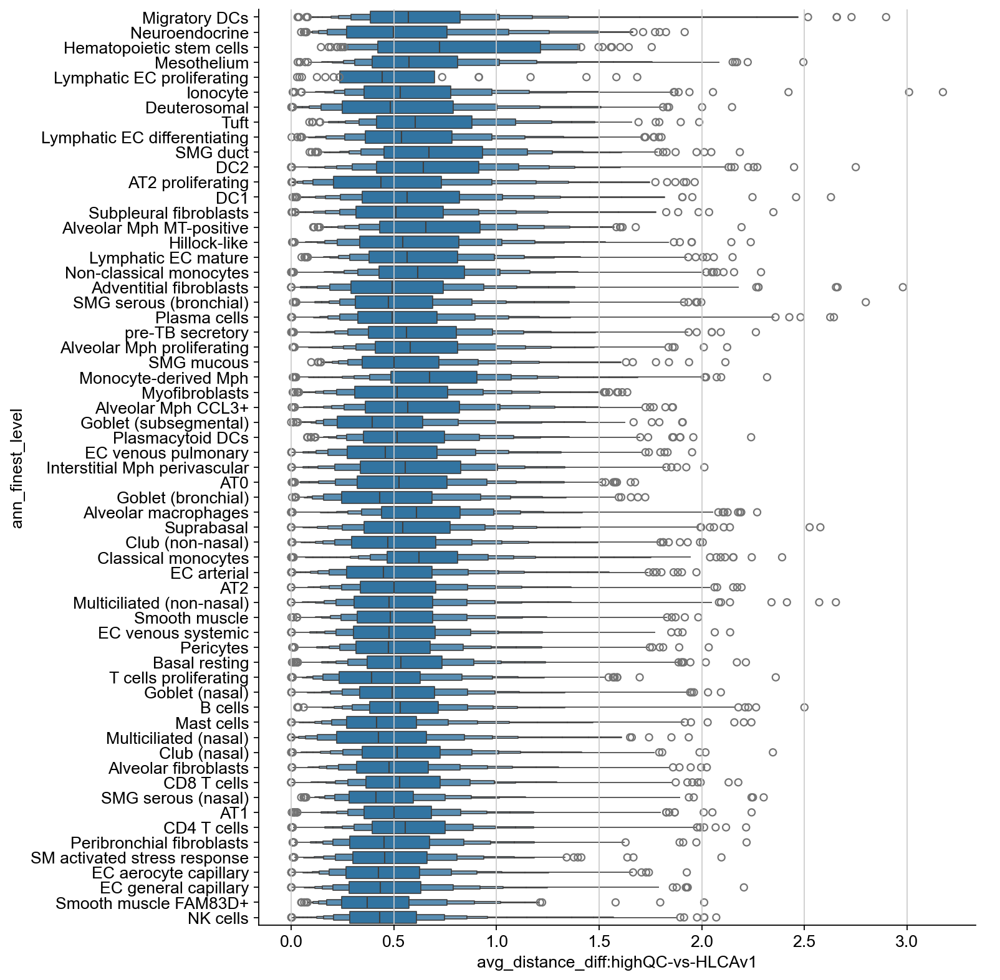

In [29]:
color = "ann_finest_level"

order = (
    adata.obs
        .groupby(
            color,
            observed=True,
        )[f"avg_distance_diff:{integration2}-vs-{integration1}"]
        .quantile(0.99)
        .sort_values(ascending=False)
        .index
)
sns.catplot(
    adata.obs,
    y=color,
    x=f"avg_distance_diff:{integration2}-vs-{integration1}",
    kind="boxen",
    aspect=1,
    height=10,
    order=order,
)


... storing 'color' as categorical


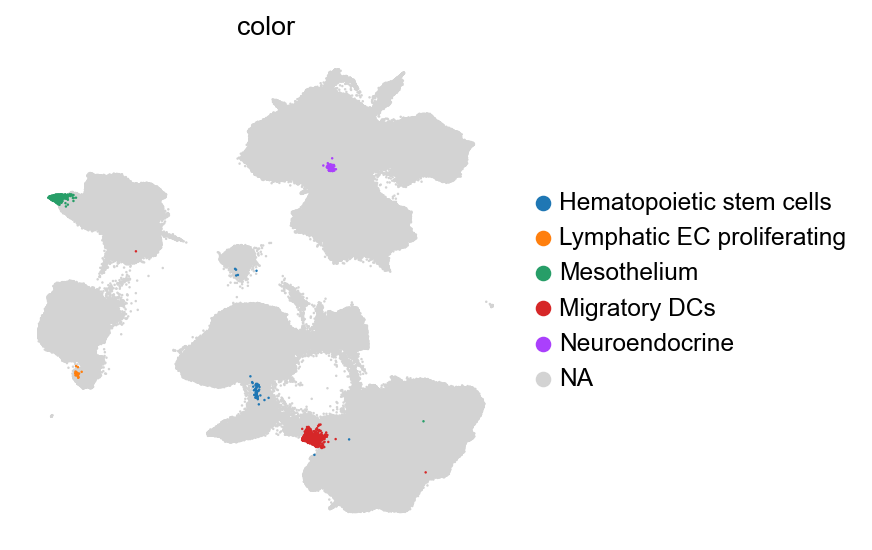

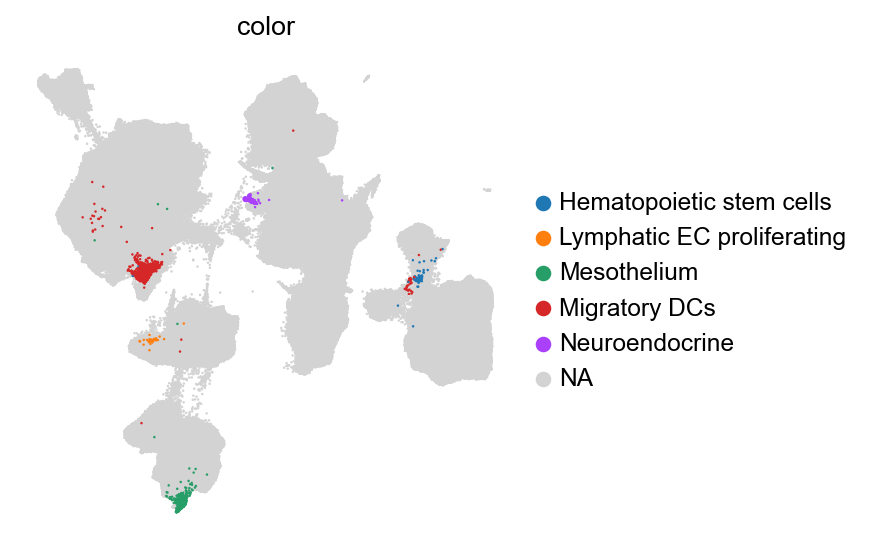

In [30]:
color = 'ann_finest_level'
mask = adata.obs[color].isin(order[:5])
# mask = adata.obs[color].str.contains('DC').fillna(False)
# mask |= adata.obs[color].isin(['Ionocyte', 'CD8 T cells', 'B cells'])
adata.obs['color'] = np.where(mask, adata.obs[color].astype(str), float('nan'))
sc.pl.embedding(
    adata,
    basis='X_umap--HLCAv1',
    color='color',
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
)

sc.pl.embedding(
    adata,
    basis='X_umap--highQC',
    color='color',
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
)

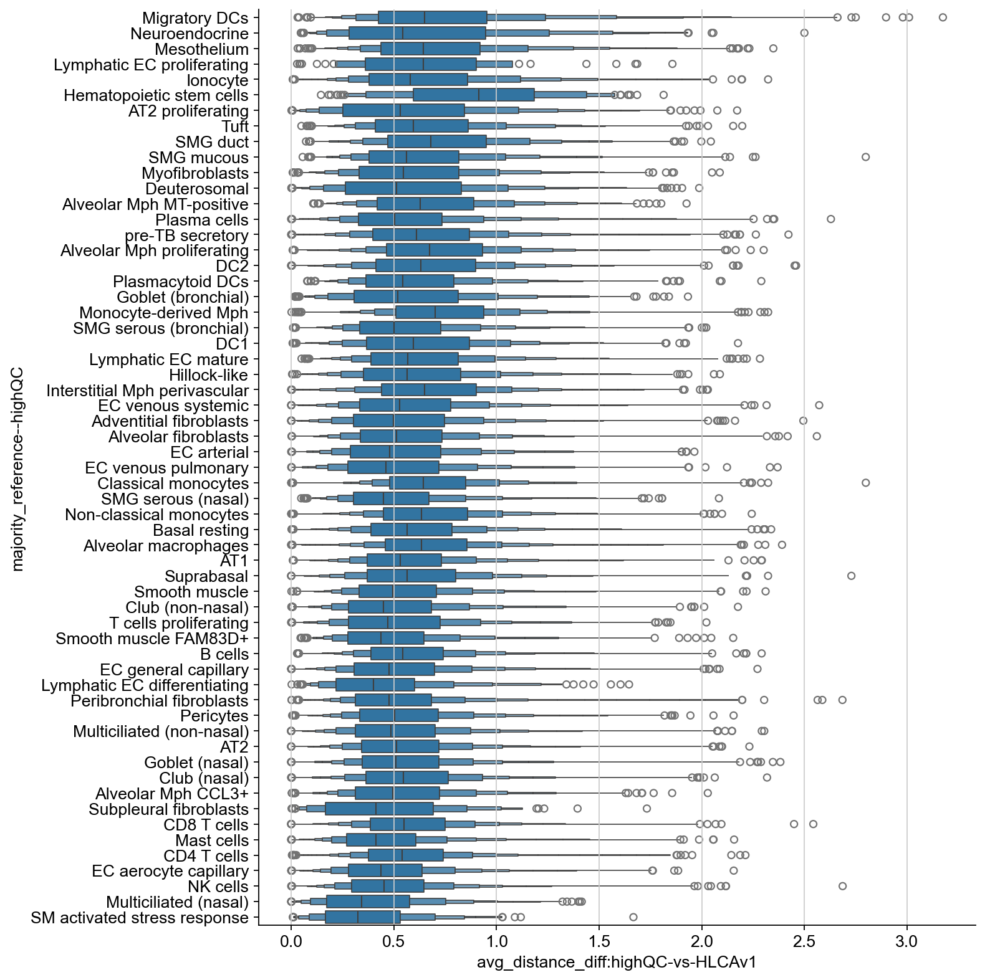

In [31]:
color = 'majority_reference--highQC'

order = (
    adata.obs
        .groupby(
            color,
            observed=True,
        )[f"avg_distance_diff:{integration2}-vs-{integration1}"]
        .quantile(0.99)
        .sort_values(ascending=False)
        .index
)
sns.catplot(
    adata.obs,
    y=color,
    x=f"avg_distance_diff:{integration2}-vs-{integration1}",
    kind="boxen",
    aspect=1,
    height=10,
    order=order,
)


... storing 'color' as categorical


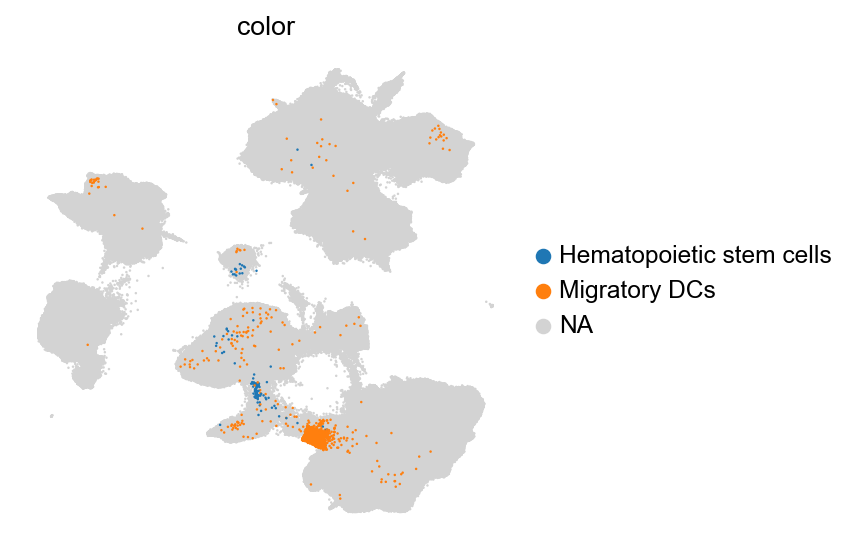

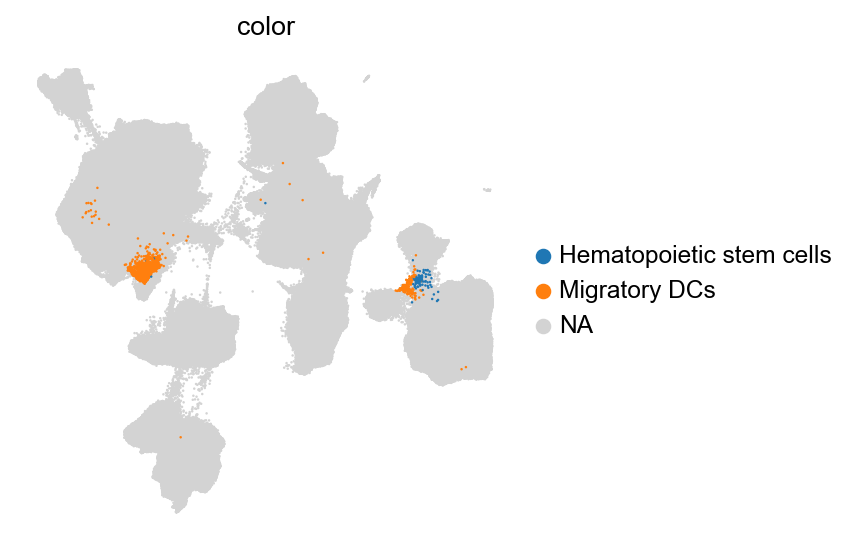

In [32]:
mask = adata.obs[color].isin(['Migratory DCs', 'Hematopoietic stem cells'])
adata.obs['color'] = np.where(mask, adata.obs[color].astype(str), float('nan'))
sc.pl.embedding(
    adata,
    basis='X_umap--HLCAv1',
    color='color',
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
)

sc.pl.embedding(
    adata,
    basis='X_umap--highQC',
    color='color',
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


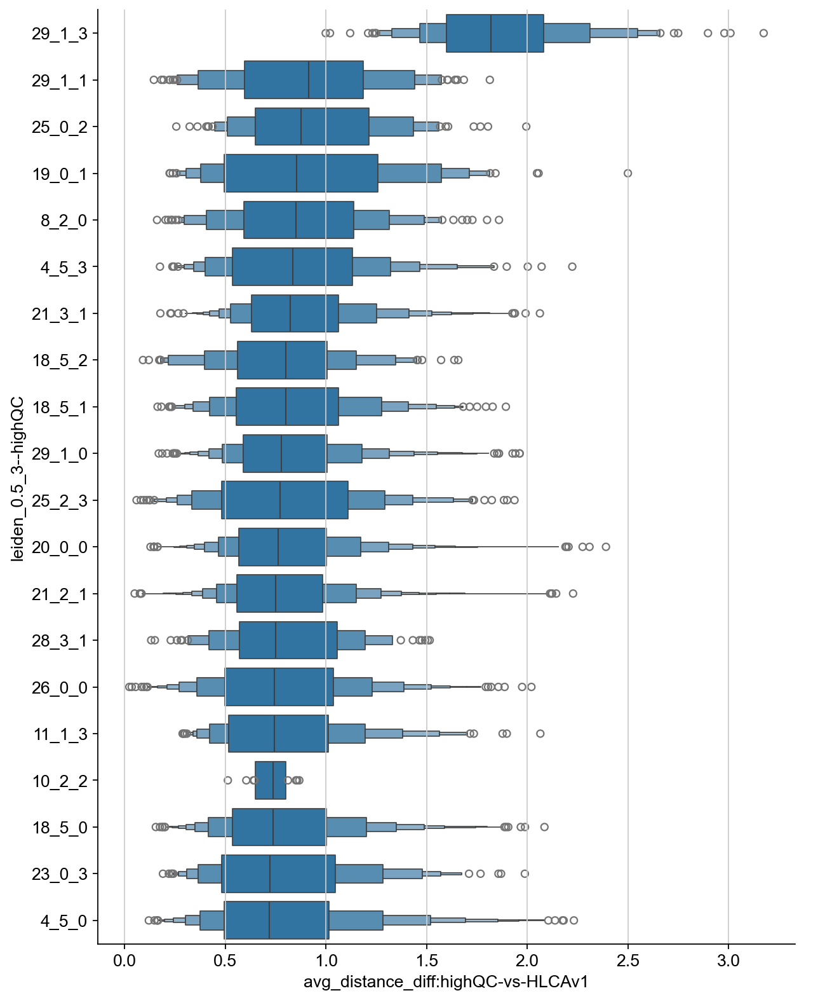

In [33]:
color = 'leiden_0.5_3--highQC'
order = (
    adata.obs
        .groupby(
            color,
            observed=True,
        )[f"avg_distance_diff:{integration2}-vs-{integration1}"]
        .quantile(0.5)
        .sort_values(ascending=False)
        .index
)[:20]
sns.catplot(
    adata.obs.query(f'`{color}`.isin(@order)'),
    y=color,
    x=f"avg_distance_diff:{integration2}-vs-{integration1}",
    kind="boxen",
    aspect=0.8,
    height=10,
    order=order,
)

... storing 'color' as categorical


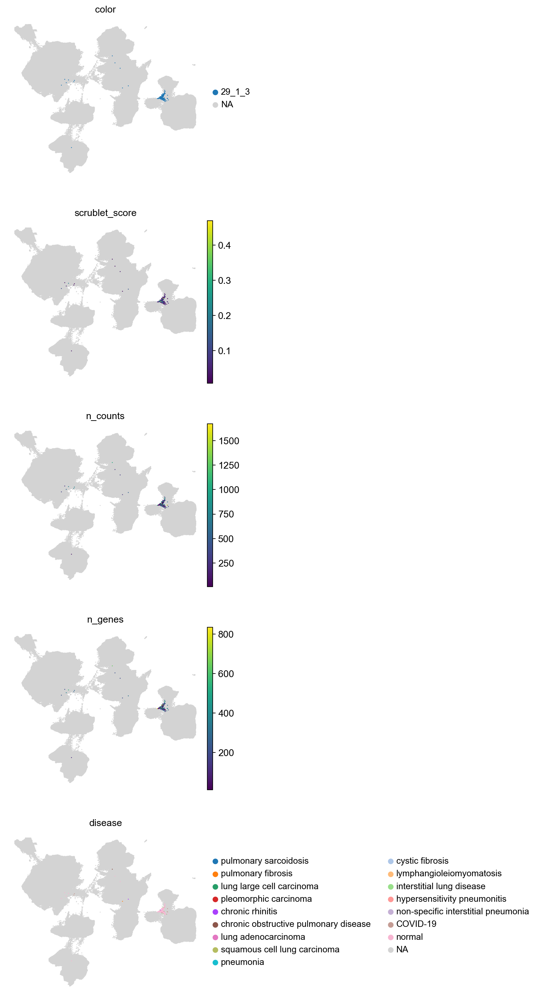

In [34]:
# mask = adata.obs[color].isin(order[:1])
mask = adata.obs[color] == cluster_of_interest
adata.obs['color'] = np.where(mask, adata.obs[color].astype(str), float('nan'))

sc.pl.embedding(
    adata,
    basis='X_umap--highQC',
    color=['color', 'scrublet_score', 'n_counts', 'n_genes', 'disease'],
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
    ncols=1,
    # verbose=False,
)

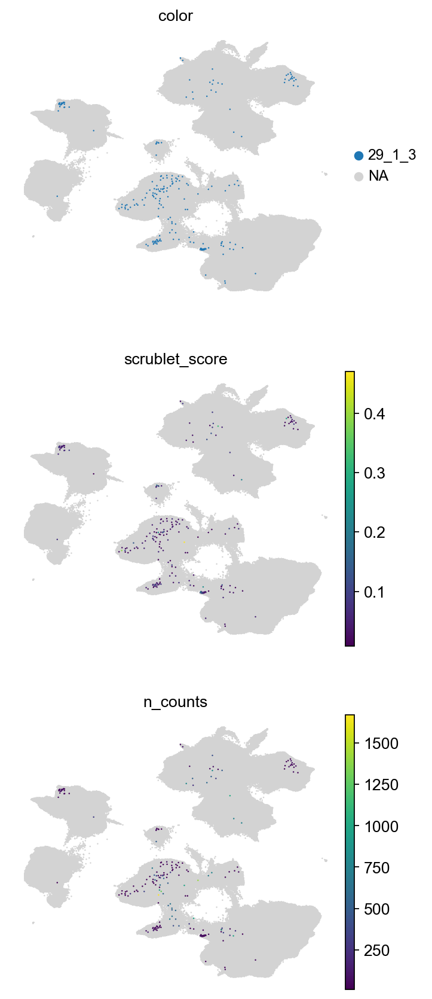

In [35]:
sc.pl.embedding(
    adata,
    basis='X_umap--HLCAv1',
    color=['color', 'scrublet_score', 'n_counts'],
    mask_obs=mask,
    size=5,
    palette=sc.pl.palettes.default_20,
    # verbose=False,
    ncols=1,
)

### DEG for cluster of interest

In [10]:
cluster_col = 'leiden_0.5_3--highQC'
cluster_of_interest = '29_1_3'

In [11]:
adata.obs['deg_col'] = adata.obs['ann_finest_level'].astype(str).where(
    adata.obs[cluster_col] != cluster_of_interest,
    other=cluster_of_interest
)

In [12]:
cts = ['Migratory DCs', 'Hematopoietic stem cells']
adata_pb = atl.pp.pseudobulk(
    adata[
        adata.obs['ann_finest_level'].isin(cts) | 
        (adata.obs[cluster_col] == cluster_of_interest)
     ].copy(),
    group_key=['sample', 'deg_col'],
    columns=['ann_finest_level', 'sample', 'deg_col', 'study', 'assay', cluster_col],
)

INFO:root:Processing group key(s) ['sample', 'deg_col']...
INFO:root:Filtering groups with at least 2 cells...
INFO:root:Aggregate 273 pseudobulks...
INFO:root:Sort and rechunk dask array by "sample--deg_col"...
/home/michaela.mueller/workspace/scAtlasTb-utils/src/scatlastb_utils/pp/pseudobulk.py:231: PerformanceWarning: Slicing with an out-of-order index is generating 112 times more chunks
  X = X[sorted_idx].rechunk((chunk_sizes, -1))
INFO:root:Aggregate 126 metadata columns...
INFO:root:Aggregating 89 categorical columns...


In [13]:
adata_pb = atl.utils.dask_compute(adata_pb)

Apply function compute_layer to X...


Dask compute:   0%|          | 0/1912 [00:00<?, ?it/s]

Apply function compute_layer to raw...
Layer raw not found, skipping...


In [14]:
sc.tl.rank_genes_groups(
    adata_pb,
    groupby='deg_col',
    # groups=['29_1_3'],
    reference='rest',
)

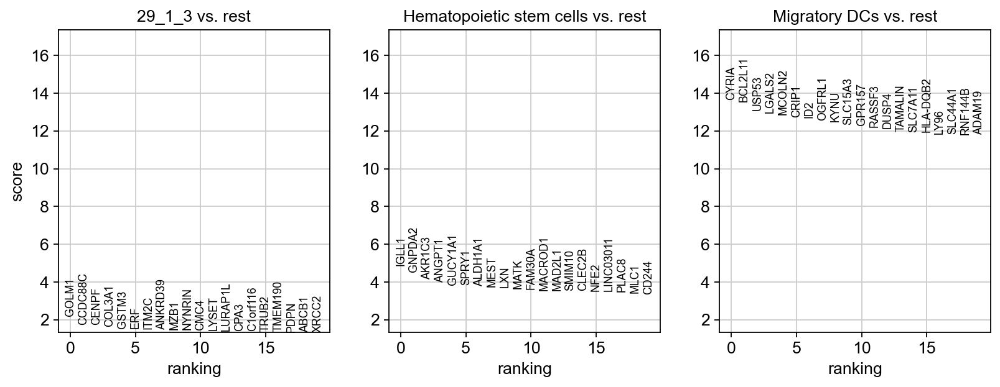

In [15]:
sc.pl.rank_genes_groups(adata_pb, gene_symbols='feature_name')

In [16]:
df_markers = sc.get.rank_genes_groups_df(
    adata_pb,
    group=cluster_of_interest,
    gene_symbols='feature_name',
)

In [17]:
df_markers

,names,scores,logfoldchanges,pvals,pvals_adj,feature_name
0,ENSG00000135052,2.209117,5.422230,5.160354e-02,1.786807e-01,GOLM1
1,ENSG00000015133,1.738598,2.778862,1.124059e-01,3.442761e-01,CCDC88C
2,ENSG00000117724,1.730133,3.954555,1.141533e-01,3.493045e-01,CENPF
3,ENSG00000168542,1.621067,8.038028,1.360638e-01,4.116018e-01,COL3A1
4,ENSG00000134202,1.547218,3.315923,1.525922e-01,4.596730e-01,GSTM3
...,...,...,...,...,...,...
56234,ENSG00000173436,-13.793407,-35.480747,7.040951e-33,7.919521e-29,MICOS10
56235,ENSG00000205155,-13.818839,-31.787573,5.741823e-33,7.919521e-29,PSENEN
56236,ENSG00000132510,-14.179528,-34.478394,3.164755e-34,5.932756e-30,KDM6B
56237,ENSG00000184182,-14.197344,-38.218414,2.741979e-34,5.932756e-30,UBE2F


In [18]:
df_markers['feature_name'].head(10).values

['GOLM1', 'CCDC88C', 'CENPF', 'COL3A1', 'GSTM3', 'ERF', 'ITM2C', 'ANKRD39', 'MZB1', 'NYNRIN']
Categories (55625, object): ['5S_rRNA', '5_8S_rRNA', '7SK', 'A1BG', ..., 'ZZEF1', 'ZZZ3', 'hsa-mir-8069-1', 'snoZ196']

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 56239 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


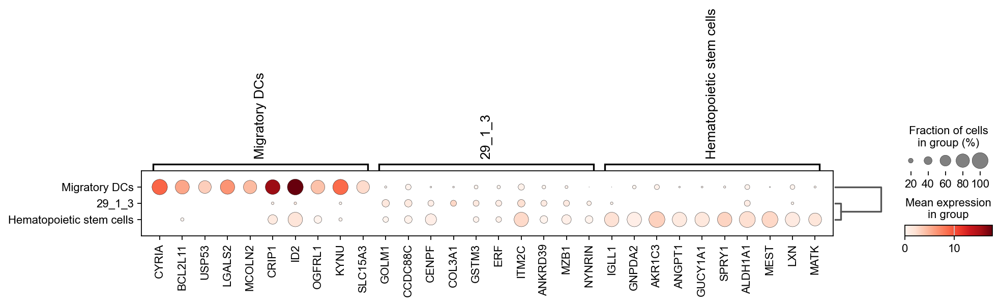

In [19]:
sc.pl.rank_genes_groups_dotplot(adata_pb, gene_symbols='feature_name')

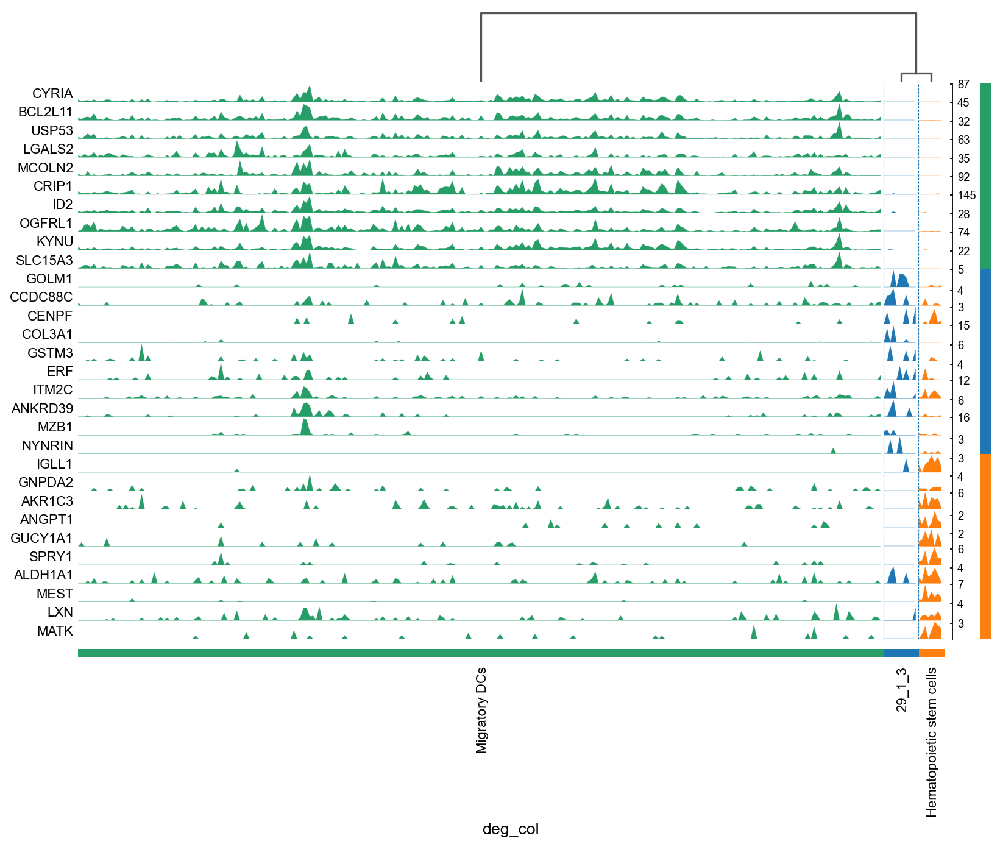

In [20]:
sc.pl.rank_genes_groups_tracksplot(adata_pb, gene_symbols='feature_name')

### Marker gene overlap for cluster of interest

In [8]:
from marker_genes_functions import get_marker_genes
from misc import run_similarity_analysis

In [21]:
doub_marker_df = get_marker_genes(
    adata_pb,
    n_genes=100,
    gene_symbols='feature_name',
)

/home/michaela.mueller/workspace/scAtlasTb_reproducibility/notebooks/QC/marker_genes_functions.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).groupby('group').head(n_genes)


In [32]:
curated_marker_df = pd.DataFrame(
    marker_genes_dict.items(),
    columns=['group', 'feature_name']
).explode('feature_name').reset_index(drop=True)

In [58]:
qc_stats = adata.obs.query(f'`{cluster_col}` == @cluster_of_interest')
qc_stats['doublet_cluster'] = qc_stats[cluster_col] == cluster_of_interest

/tmp/ipykernel_335399/1524484504.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  qc_stats['doublet_cluster'] = qc_stats[cluster_col] == cluster_of_interest


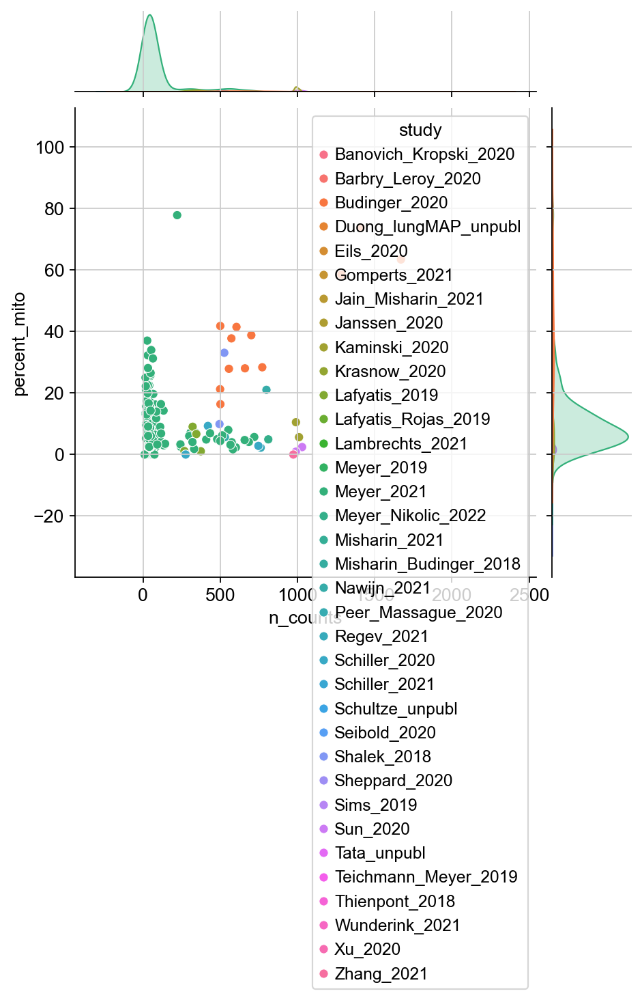

In [65]:
sns.jointplot(
    qc_stats,
    x='n_counts',
    y='percent_mito',
    hue='study',
)

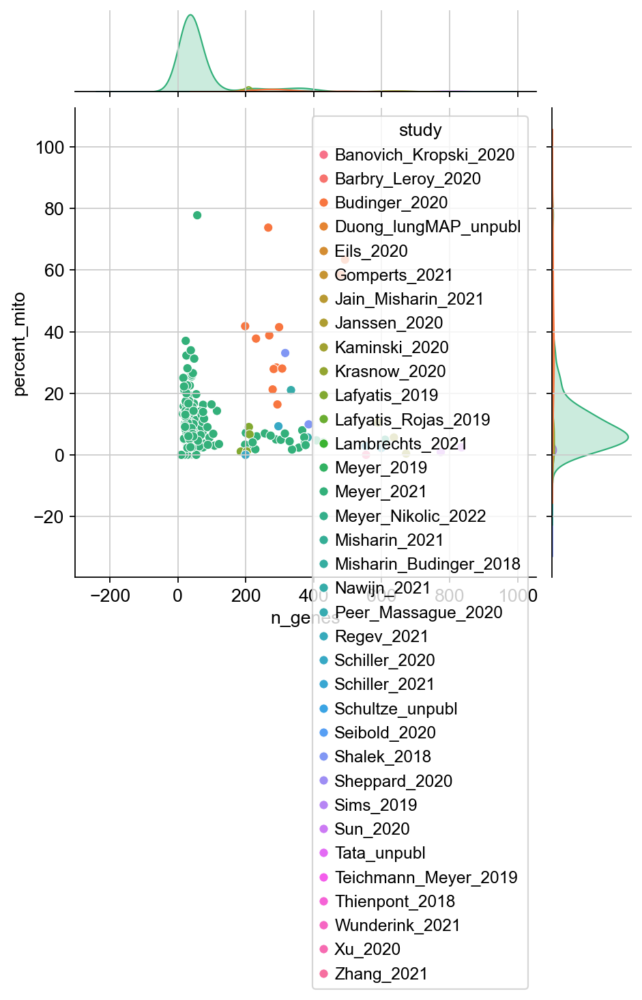

In [66]:
sns.jointplot(
    qc_stats,
    x='n_genes',
    y='percent_mito',
    hue='study',
)

In [39]:
qc_stats.value_counts(
    ['study', 'sample', 'core_or_extension', 'qc_status']
)

study               sample             core_or_extension  qc_status
Meyer_2021          5841STDY7991475    extension          failed       170
Budinger_2020       Sample_10          extension          failed         7
Meyer_2021          WSSS8062682        extension          failed         5
Lafyatis_2019       SSC 1              extension          failed         3
Meyer_2021          WSSS8062679        extension          failed         3
                    WSSS8062681        extension          failed         2
Budinger_2020       Sample_9           extension          failed         2
Meyer_2021          WSSS_A_LNG8620063  extension          failed         2
                    WSSS_A_LNG8620064  extension          failed         2
                    WSSS_A_LNG8620065  extension          failed         2
                    WSSS_A_LNG8620066  extension          failed         2
Kaminski_2020       439C-b             extension          failed         1
Budinger_2020       Sample_21   

In [67]:
adata.obs.columns

Index(['suspension_type', 'donor_id--HLCAv1', 'is_primary_data--HLCAv1',
       'assay_ontology_term_id', 'cell_type_ontology_term_id',
       'development_stage_ontology_term_id', 'disease_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id',
       'sex_ontology_term_id',
       ...
       'transf_ann_level_5_label--deNovo', 'transf_ann_level_5_uncert--deNovo',
       'leiden_0.5_1--deNovo', 'leiden_0.5_2--deNovo', 'leiden_0.5_3--deNovo',
       'majority_reference--deNovo', 'majority_consensus',
       'majority_consensus_agreement', 'majority_consensus_low_agreement',
       'deg_col'],
      dtype='object', length=125)

In [75]:
qc_stats.groupby(
    ['study', 'core_or_extension', 'qc_status']
)['n_genes'].mean().dropna()

/tmp/ipykernel_335399/3815842447.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  qc_stats.groupby(


study               core_or_extension  qc_status
Budinger_2020       extension          failed       307.000000
Kaminski_2020       extension          failed       630.500000
                                       passed       636.000000
Lafyatis_2019       extension          failed       202.000000
Meyer_2021          extension          failed        67.759163
Meyer_Nikolic_2022  extension          failed       610.000000
Nawijn_2021         core               failed       357.500000
Regev_2021          extension          passed       599.000000
Schiller_2020       extension          failed       349.333344
Shalek_2018         extension          failed       350.500000
Sun_2020            extension          passed       804.500000
Zhang_2021          extension          passed       554.000000
Name: n_genes, dtype: float32

## Compare low QC across models

### Entropy analysis

In [28]:
from scipy.stats import entropy

In [29]:
group_keys = [
    # 'leiden_0.5_1--highQC',
    # 'leiden_0.5_1--HLCAv1',
    'leiden_0.5_2--HLCAv1',
    'leiden_0.5_2--highQC',
    'leiden_0.5_3--HLCAv1',
    'leiden_0.5_3--highQC',
]

In [30]:
for group_key in group_keys:
    adata.obs[f'qc_entropy_{group_key}'] = adata.obs.groupby(
        group_key, observed=True
    )['qc_status'].transform(
        lambda x: entropy(x.value_counts())
    )

2026-05-04 08:47:28 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 08:47:28 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 08:47:28 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


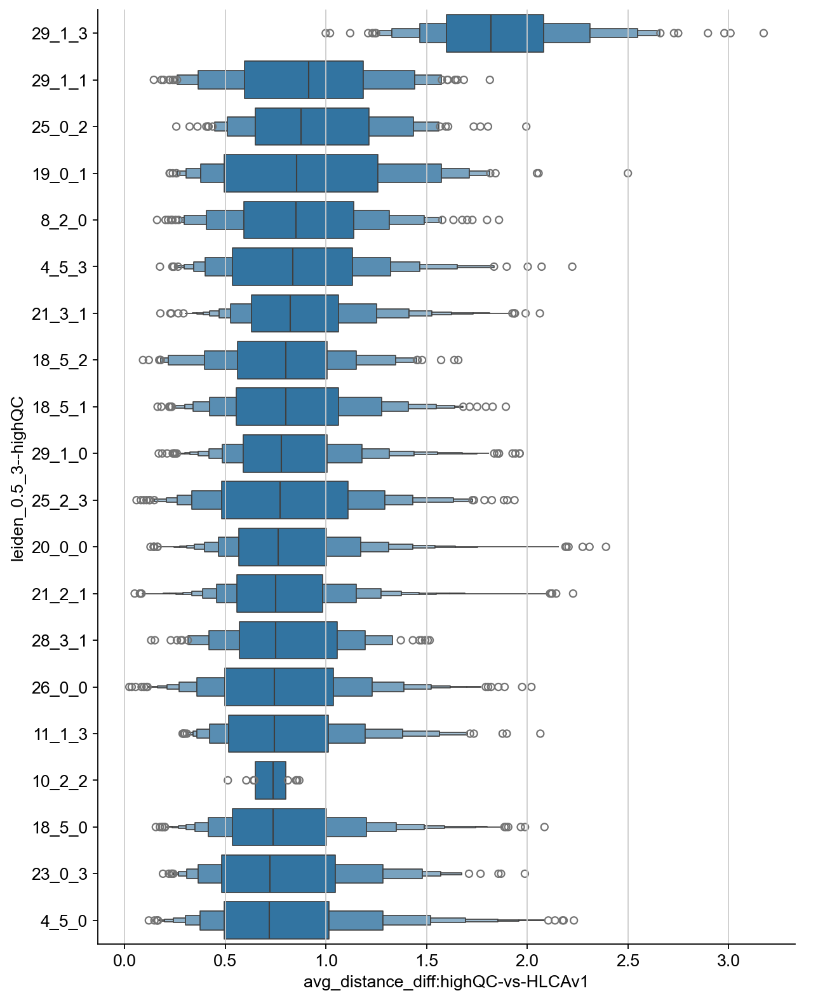

In [31]:
color = 'leiden_0.5_3--highQC'
order = (
    adata.obs
        .groupby(
            color,
            observed=True,
        )[f"avg_distance_diff:{integration2}-vs-{integration1}"]
        .quantile(0.5)
        .sort_values(ascending=False)
        .index
)[:20]
sns.catplot(
    adata.obs.query(f'`{color}`.isin(@order)'),
    y=color,
    x=f"avg_distance_diff:{integration2}-vs-{integration1}",
    kind="boxen",
    aspect=0.8,
    height=10,
    order=order,
)

/tmp/ipykernel_411048/1653365537.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(group_key)[


<Axes: >

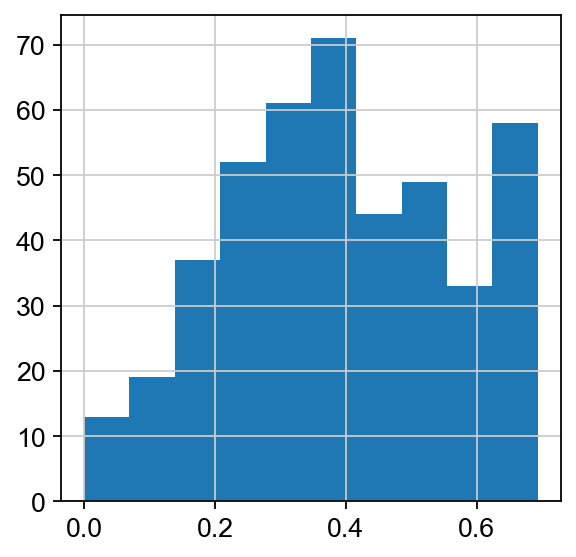

In [41]:
group_key = 'leiden_0.5_3--highQC'
order = (
    adata.obs
        .groupby(
            color,
            observed=True,
        )[f'qc_entropy_{group_key}']
        .quantile(0.5)
        .sort_values(ascending=False)
        .index
)[:20]

adata.obs.groupby(group_key)[
    f'qc_entropy_{group_key}'
].mean().hist()

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

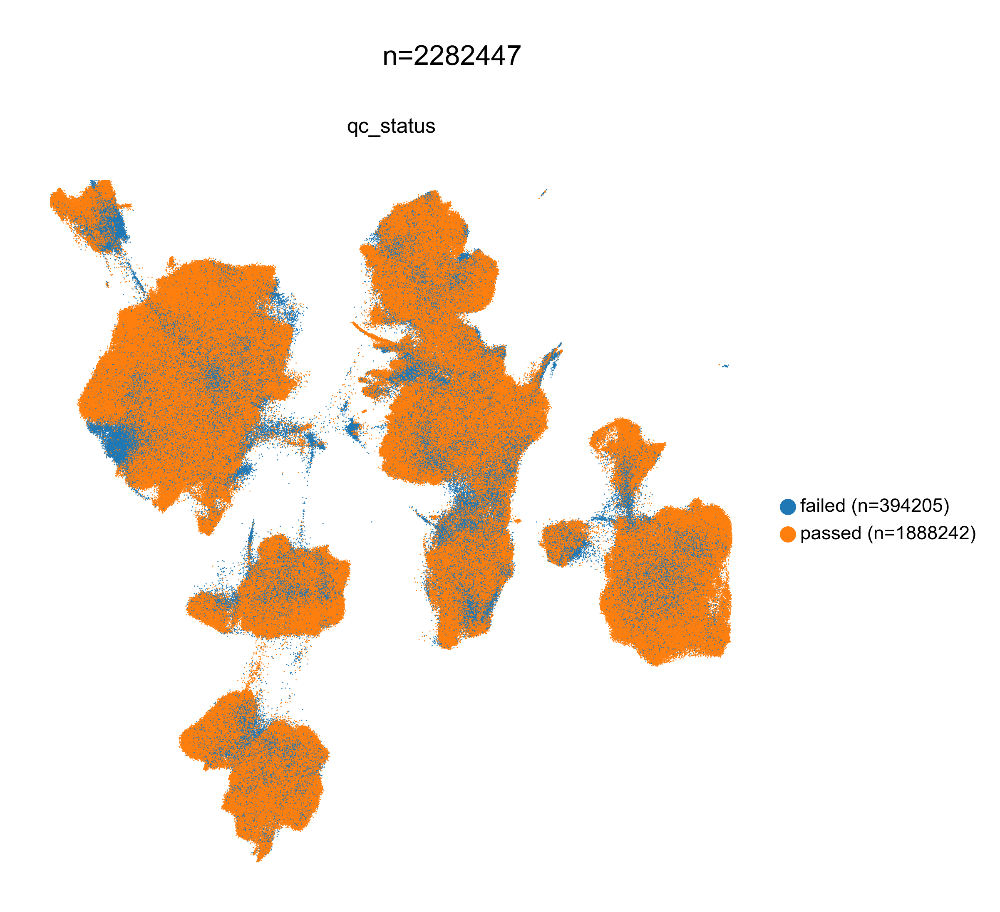

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

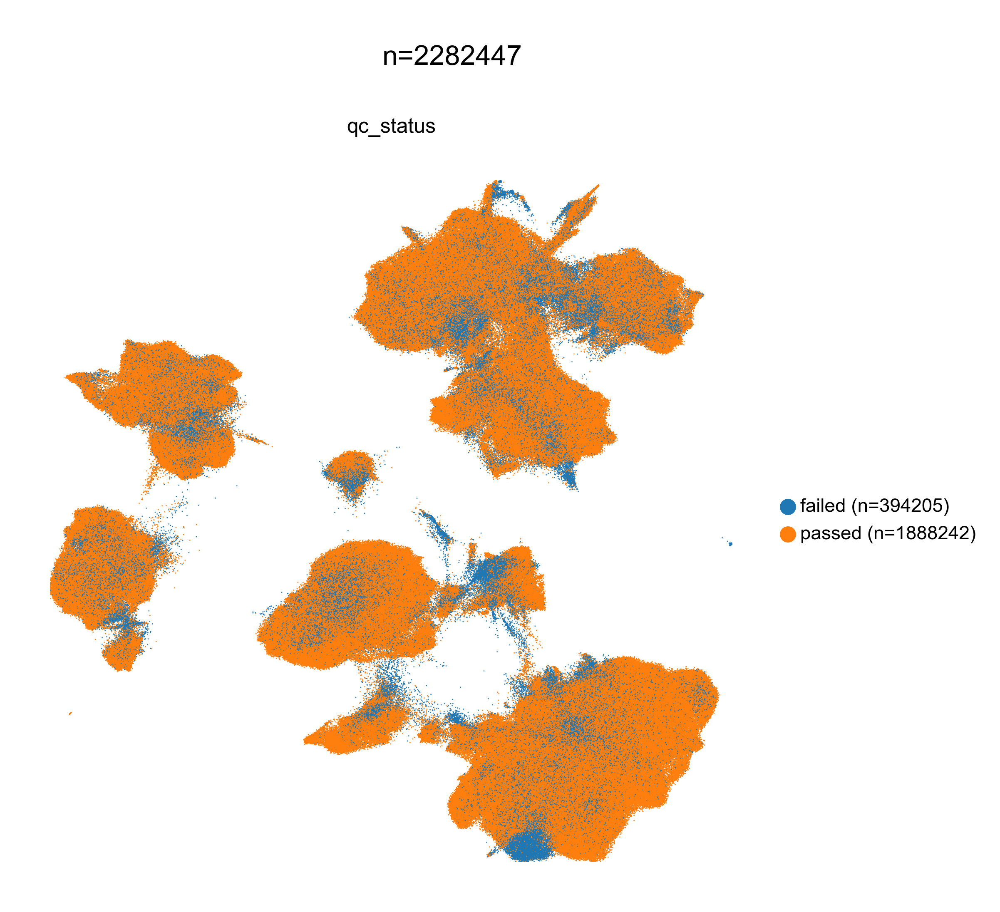

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

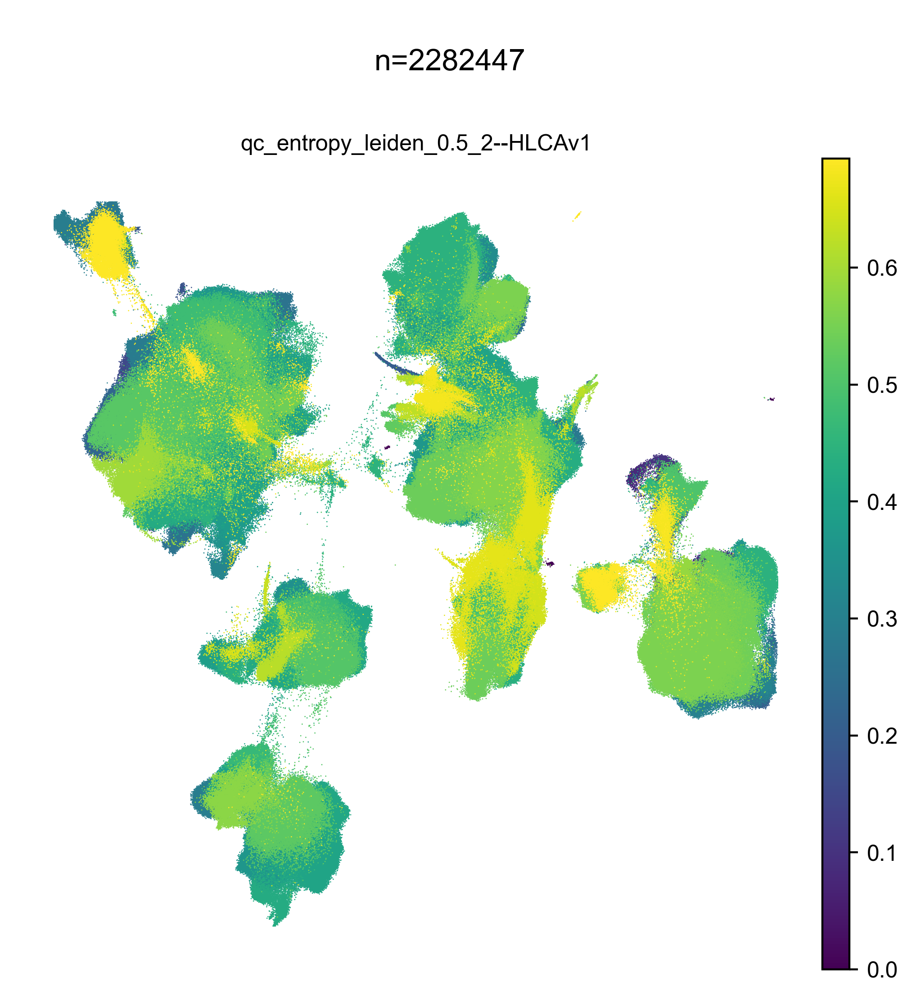

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

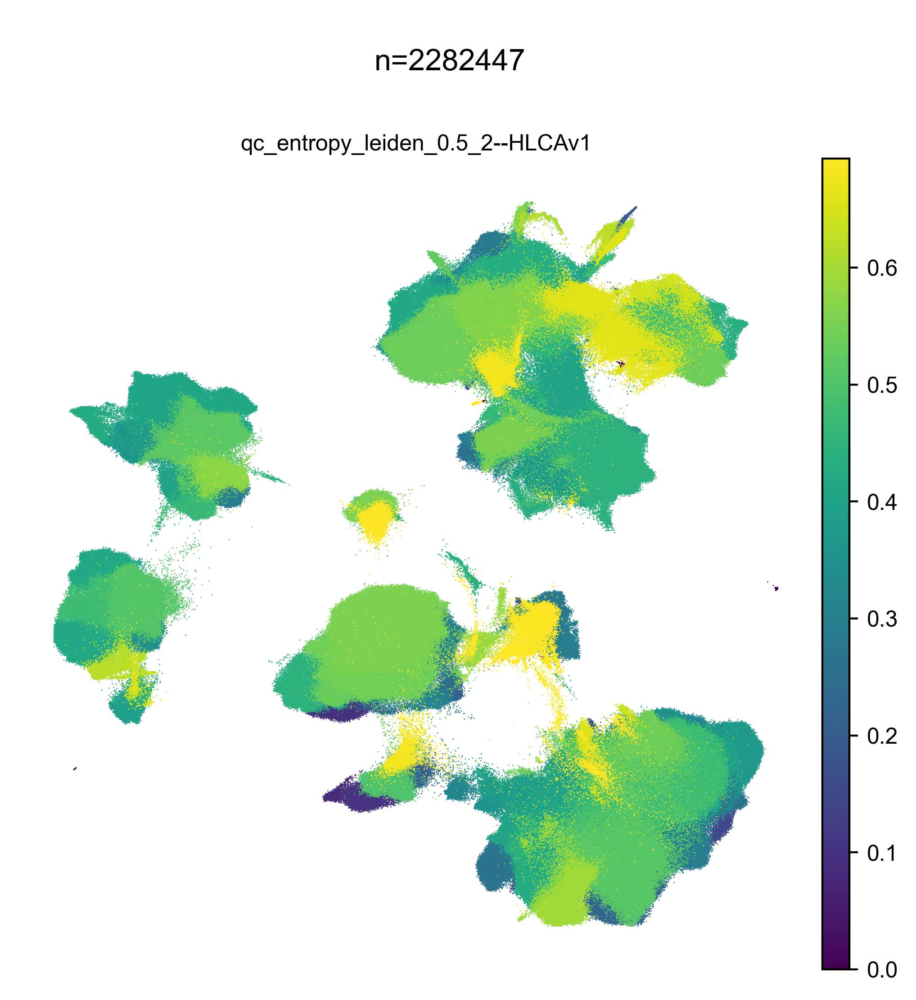

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

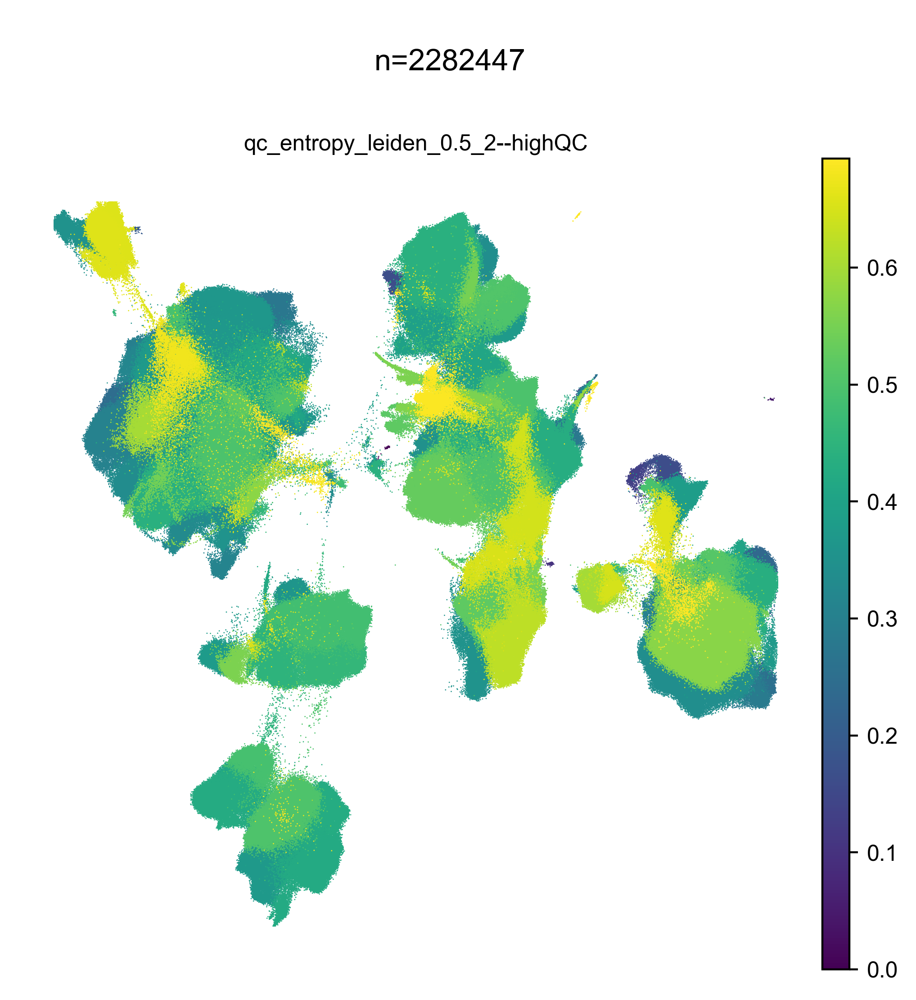

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

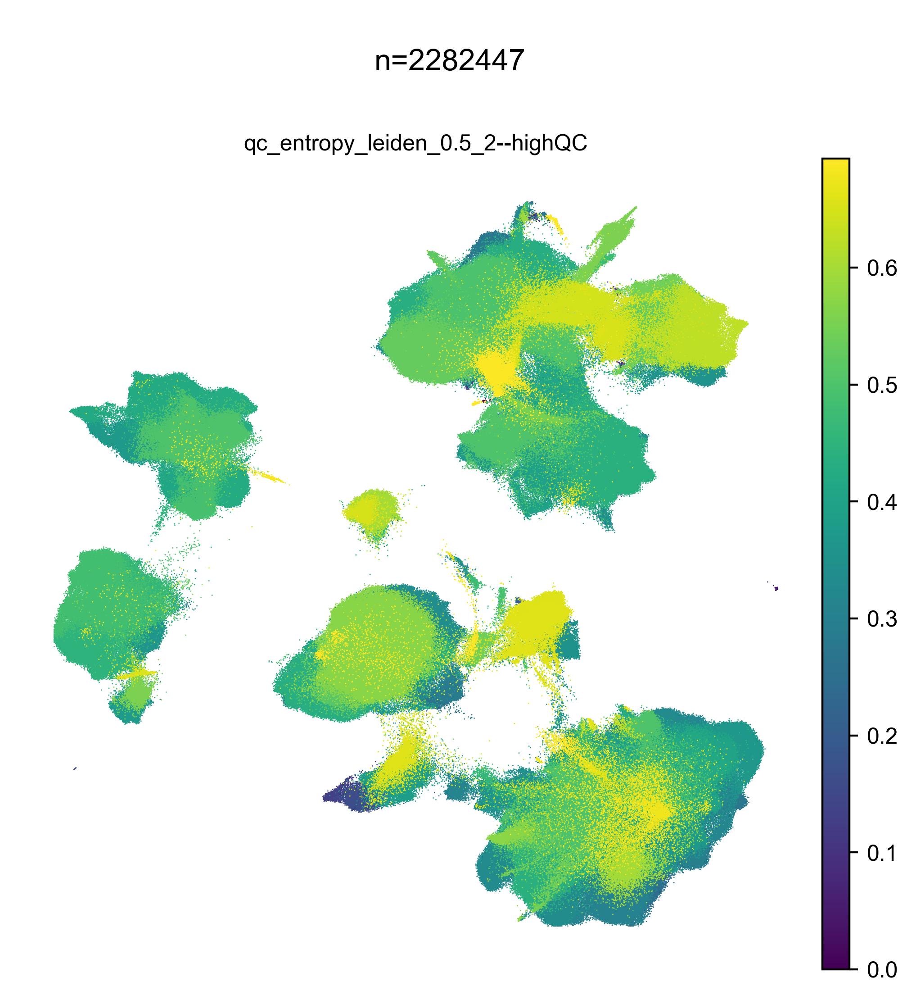

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

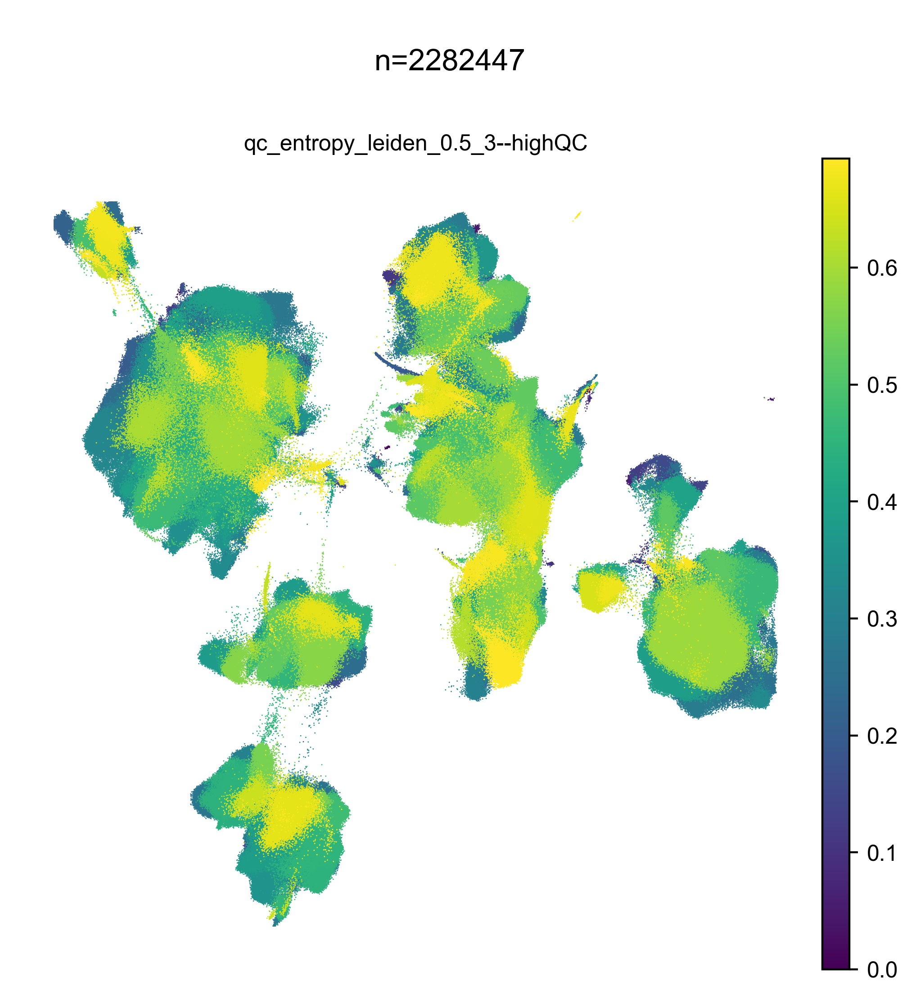

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

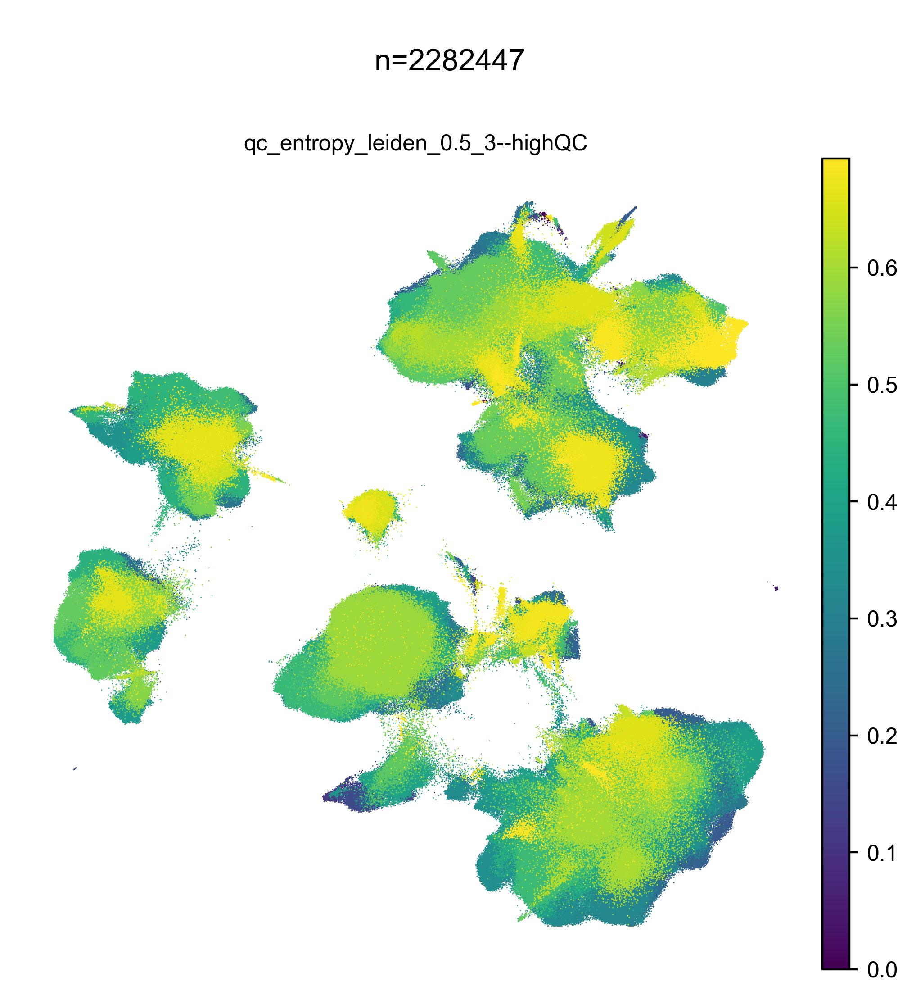

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

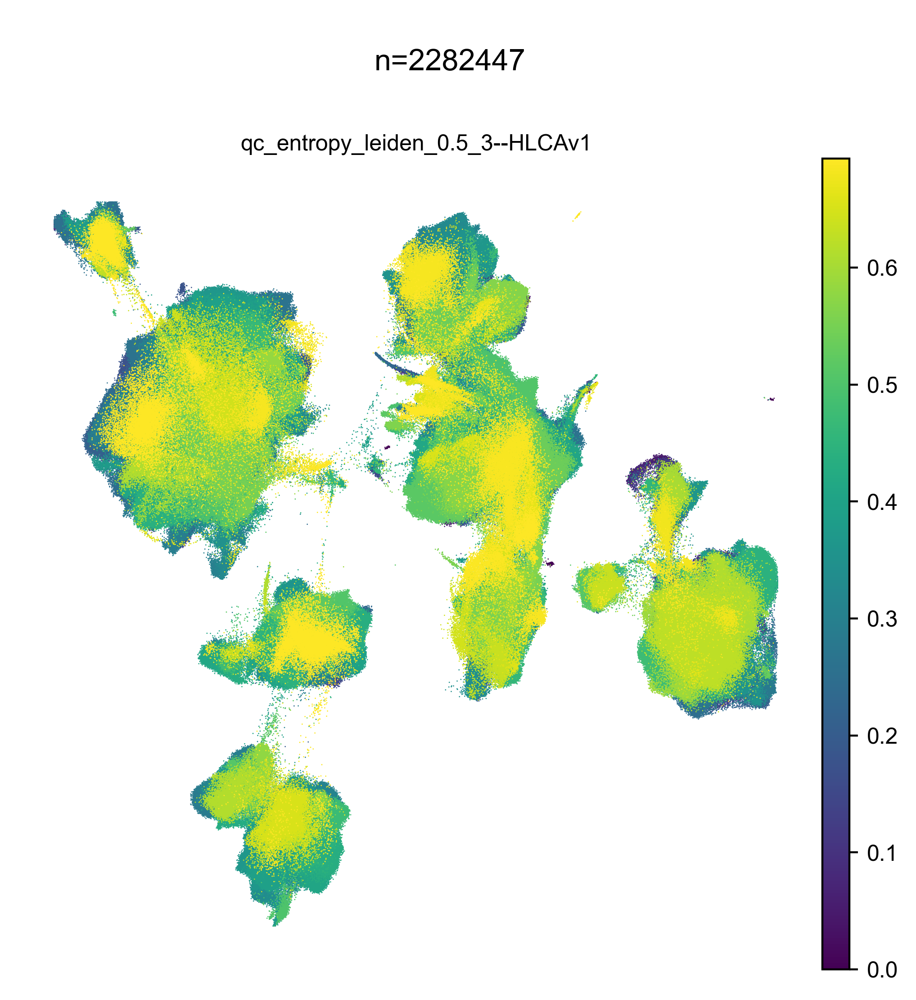

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

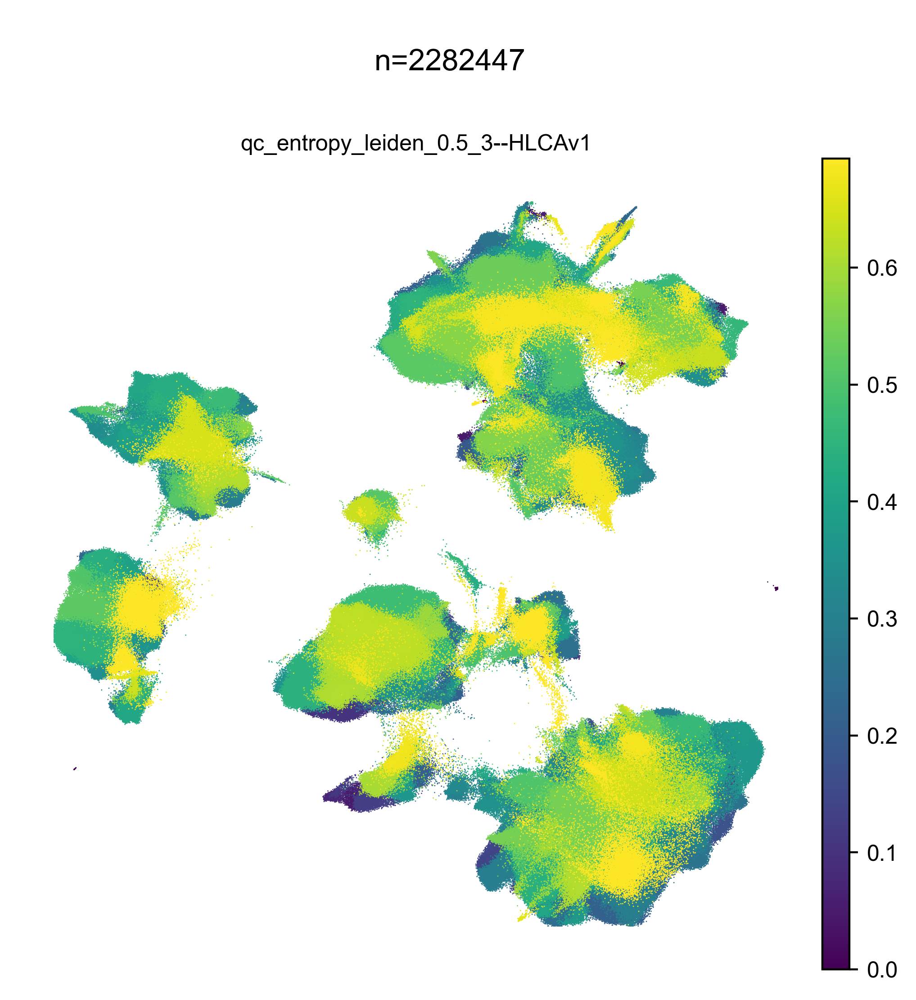

Plotting colors: 100%|██████████| 1/1 [00:10<00:00, 10.23s/it]


In [105]:
for color in ['qc_status']+[
    f'qc_entropy_{group_key}' for group_key in group_keys
]:
    atl.pl.embedding(
        adata,
        basis='X_umap--highQC',
        color=color,
        verbose=False,
    )
    atl.pl.embedding(
        adata,
        basis='X_umap--HLCAv1',
        color=color,
        verbose=False,
    )

In [97]:
def plot_scatter_per_group(
    adata,
    group_key,
    x,
    y,
    hue,
    anno_query=None,
    annotate_text=True,
    **kwargs,
):
    from adjustText import adjust_text

    # 1. Aggregate
    plot_df = adata.obs.groupby(group_key, observed=True)[[x, y, hue]].agg(
        lambda c: c.mean() 
            if pd.api.types.is_numeric_dtype(c)
            else c.value_counts().index[0]
    )
    
    # 2. Filter & Mask
    if not anno_query:
        anno_query = f'`{y}`.abs() > {plot_df[y].quantile(0.99)}'
    
    anno_df = plot_df.query(anno_query)
    # Highlight matching labels, turn everything else to "Other"
    hues = np.where(plot_df.index.isin(anno_df.index), plot_df[hue], "Other")

    # 3. Plot
    ax = sns.scatterplot(
        data=plot_df,
        x=x,
        y=y,
        hue=hues,
        **kwargs
    )
    
    # 4. Labels
    if annotate_text:
        texts = [plt.text(r[x], r[y], i) for i, r in anno_df.iterrows()]
        adjust_text(
            texts,
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
            expand=(1.3, 1.5),
            force_text=(0.5, 0.8),
            force_points=(0.3, 0.5),
            lim=100,
            only_move={'points': 'y', 'texts': 'xy'},
        )
    
    # 5. Legend
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    
    return ax

<Axes: xlabel='qc_entropy_leiden_0.5_3--highQC', ylabel='spearman_correlation:highQC-vs-HLCAv1'>

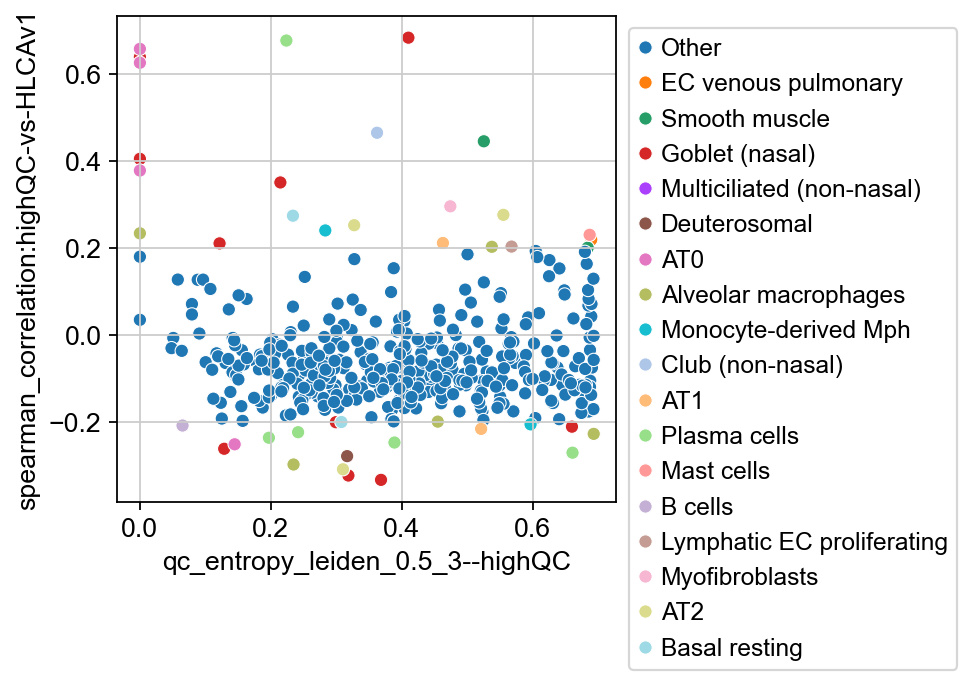

In [85]:
plot_scatter_per_group(
    adata,
    group_key='leiden_0.5_3--highQC',
    x='qc_entropy_leiden_0.5_3--highQC',
    y='spearman_correlation:highQC-vs-HLCAv1',
    hue='ann_finest_level',
    anno_query='`spearman_correlation:highQC-vs-HLCAv1`.abs() > 0.2',
    annotate_text=False,
)

<Axes: xlabel='qc_entropy_leiden_0.5_3--highQC', ylabel='spearman_correlation:highQC-vs-HLCAv1'>

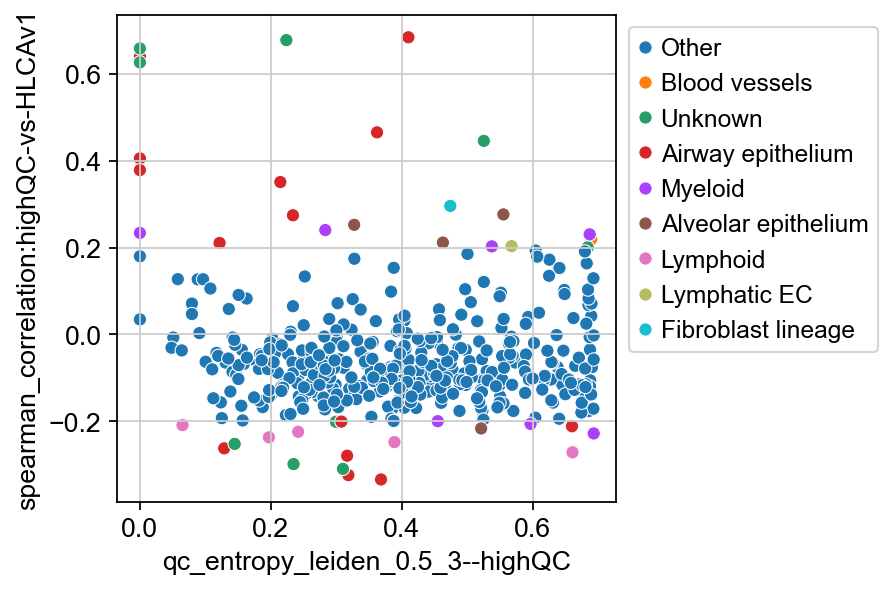

In [101]:
plot_scatter_per_group(
    adata,
    group_key='leiden_0.5_3--highQC',
    x='qc_entropy_leiden_0.5_3--highQC',
    y='spearman_correlation:highQC-vs-HLCAv1',
    hue='ann_level_2',
    anno_query='`spearman_correlation:highQC-vs-HLCAv1`.abs() > 0.2',
    annotate_text=False,
)

<Axes: xlabel='qc_entropy_leiden_0.5_3--highQC', ylabel='avg_distance_diff:highQC-vs-HLCAv1'>

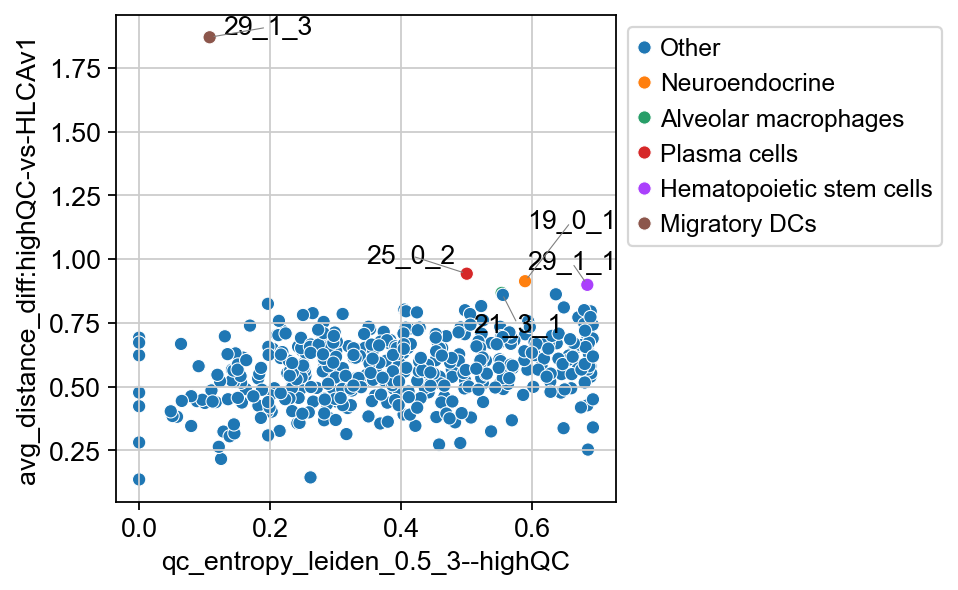

In [86]:
plot_scatter_per_group(
    adata,
    group_key='leiden_0.5_3--highQC',
    x='qc_entropy_leiden_0.5_3--highQC',
    y='avg_distance_diff:highQC-vs-HLCAv1',
    hue='ann_finest_level',
    # anno_query='`avg_distance_diff:highQC-vs-HLCAv1` > 0.3'
)

<Axes: xlabel='qc_entropy_leiden_0.5_3--highQC', ylabel='scrublet_score'>

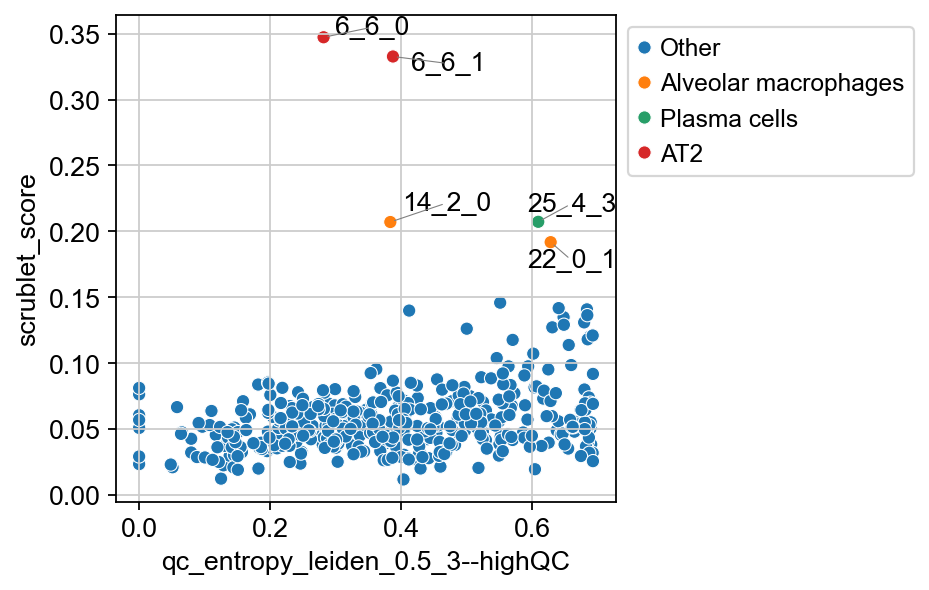

In [100]:
plot_scatter_per_group(
    adata,
    group_key='leiden_0.5_3--highQC',
    x='qc_entropy_leiden_0.5_3--highQC',
    y='scrublet_score',
    hue='ann_finest_level',
    anno_query='`scrublet_score` > 0.15',
)

<Axes: xlabel='qc_entropy_leiden_0.5_3--highQC', ylabel='scrublet_score'>

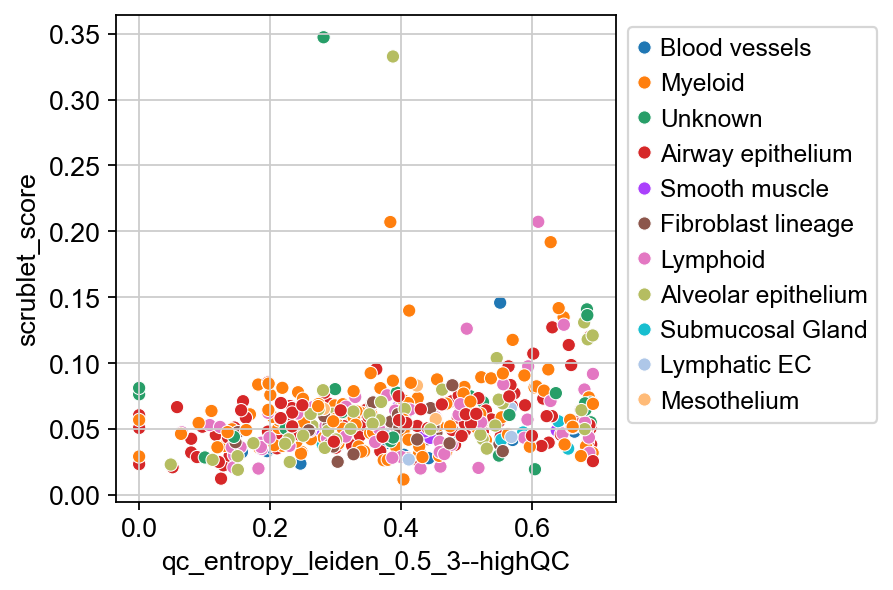

In [95]:
plot_scatter_per_group(
    adata,
    group_key='leiden_0.5_3--highQC',
    x='qc_entropy_leiden_0.5_3--highQC',
    y='scrublet_score',
    hue='ann_level_2',
    annotate_text=False,
    anno_query='`scrublet_score` > 0'
)